<a href="https://colab.research.google.com/github/JManuelRG/MLRaman/blob/main/Pretratamiento/Matriz_RamanCiprofloxacino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os

# Montar Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np

## Código para trabajar directamente desde Drive y no cargar excel cada que entro al colab

In [ ]:
# Definir la ruta permanente en Google Drive
ruta_archivo = "/content/drive/MyDrive/Raman_Ciprofloxacino/MATRIZ-FARMACOS-FALCON.xlsx"

if os.path.exists(ruta_archivo):
    print("¡Éxito! Archivo encontrado correctamente en Google Drive.")
    # Para cargar el archivo Excel
    datos = pd.read_excel(ruta_archivo)
    print("Datos cargados exitosamente en la variable 'datos'.")
else:
    print("Error: No se encontró el archivo en la ruta especificada.")
    print("Por favor, verifica que la carpeta 'Raman_Ciprofloxacino' y el archivo 'MATRIZ-FARMACOS-FALCON.xlsx' existan en tu Google Drive.")

¡Éxito! Archivo encontrado correctamente en Google Drive.
Datos cargados exitosamente en la variable 'datos'.


In [ ]:
ruta_archivo = "/content/drive/MyDrive/Raman_Ciprofloxacino/MATRIZ-FARMACOS-FALCON.xlsx"

datos = pd.read_excel(ruta_archivo, header=None)

X = datos.iloc[:, :600].values
WD = datos.iloc[:, 601].values

X_espectros = X.T

print("Dimensiones del DataFrame con header=None:", datos.shape)
print("Matriz original (X):", X.shape)
print("Eje Raman (WD):", WD.shape)
print("Matriz de espectros (X_espectros):", X_espectros.shape)

Dimensiones del DataFrame con header=None: (3319, 602)
Matriz original (X): (3319, 600)
Eje Raman (WD): (3319,)
Matriz de espectros (X_espectros): (600, 3319)


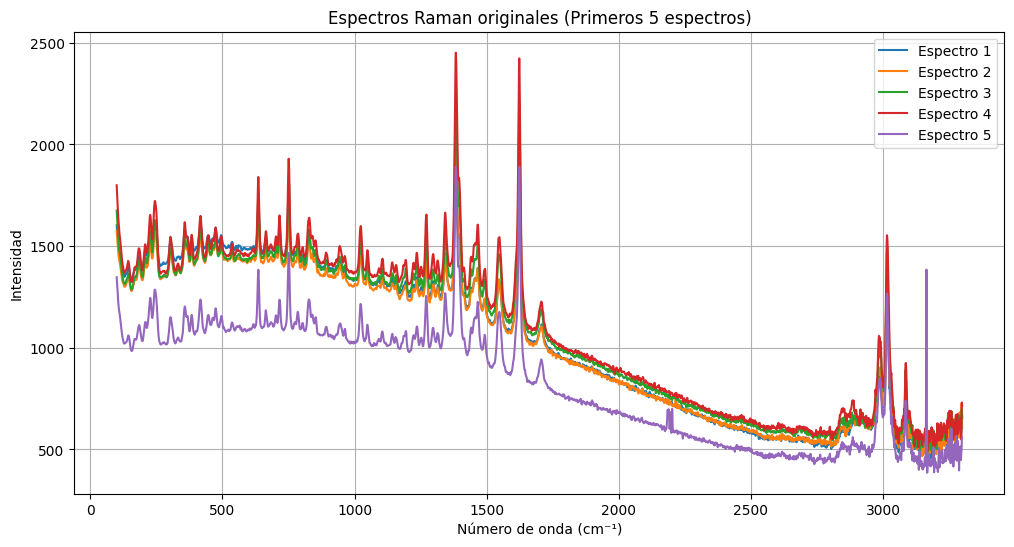

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(5):
    plt.plot(WD, X_espectros[i], label=f"Espectro {i+1}")

plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Intensidad")
plt.title("Espectros Raman originales (Primeros 5 espectros)")
plt.legend()
plt.grid(True)
plt.show()

## Primer deteccion de anomalias (espectro 5)

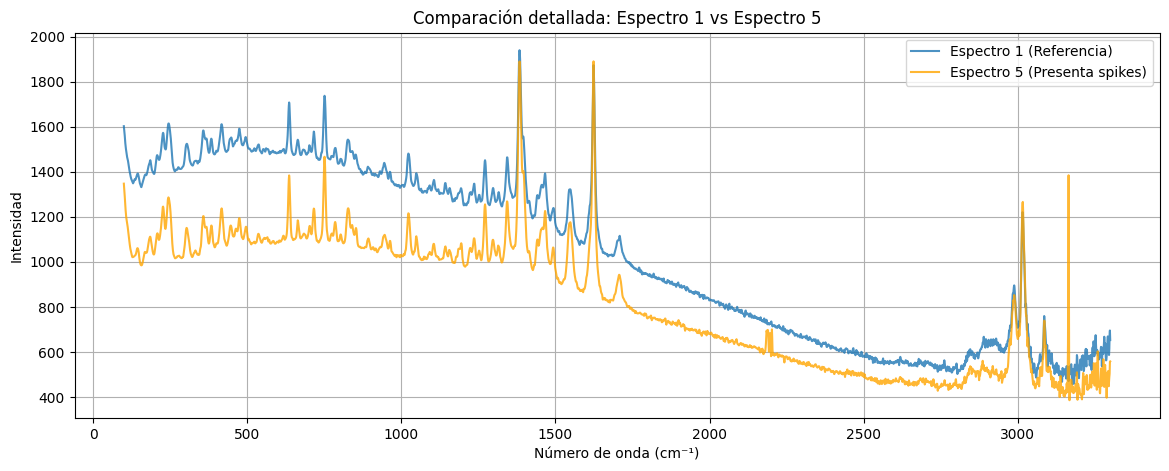

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(WD, X_espectros[0], label="Espectro 1 (Referencia)", alpha=0.8)
plt.plot(WD, X_espectros[4], label="Espectro 5 (Presenta spikes)", alpha=0.8, color='orange')
plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Intensidad")
plt.title("Comparación detallada: Espectro 1 vs Espectro 5")
plt.legend()
plt.grid(True)
plt.show()

# comparación espectro 1vs5

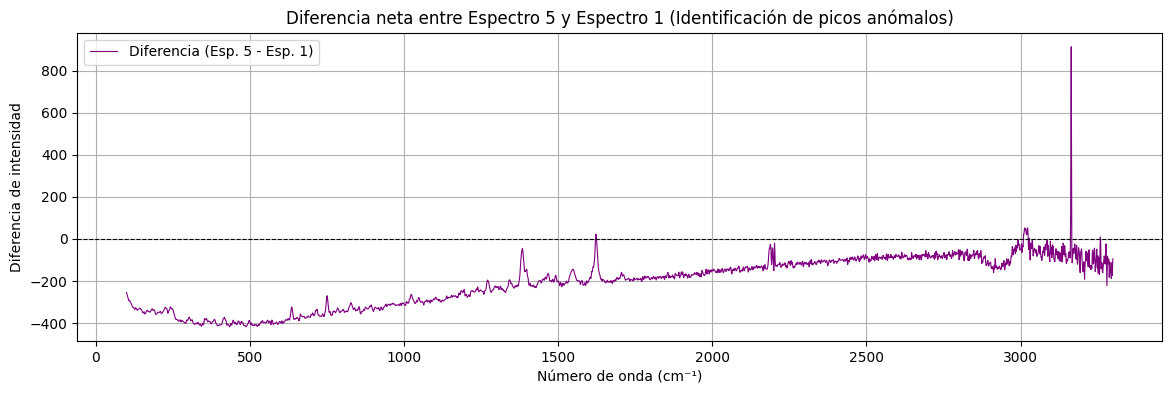

In [ ]:
diferencia_1_5 = X_espectros[4] - X_espectros[0]

plt.figure(figsize=(14, 4))
plt.plot(WD, diferencia_1_5, color='purple', label="Diferencia (Esp. 5 - Esp. 1)", linewidth=0.8)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Diferencia de intensidad")
plt.title("Diferencia neta entre Espectro 5 y Espectro 1 (Identificación de picos anómalos)")
plt.legend()
plt.grid(True)
plt.show()

# resta del espectro 1 vs 5 para ver sus diferencias

## Primer contacto con los filtros para la eliminación de spikes o picos cosmicos

## Alpicación de filtro de mediana con un umbral de 10

## utilizamos el espectro 5 como ejemplo

In [ ]:
from scipy.ndimage import median_filter

def detectar_spikes(espectro, ventana=7, umbral=10):

    # ventana: Definne la cantidad de puntos vecinos que se analizan (3-1-3)
    # umbral: es limite o frontera matemática

    base_local = median_filter(espectro, size=ventana, mode="nearest")
    residuo = espectro - base_local
    sigma_robusta = 1.4826 * np.median(np.abs(residuo - np.median(residuo)))
    z = residuo / sigma_robusta
    indices = np.where(np.abs(z) > umbral)[0]
    return indices, z, base_local

# Espectro 5 (índice 4) y espectro 1 (índice 0)
esp5 = X_espectros[4]
esp1 = X_espectros[0]

idx5, z5, base5 = detectar_spikes(esp5)
idx1, z1, base1 = detectar_spikes(esp1)

print(f"Candidatos en espectro 5: {len(idx5)}")
print(f"Candidatos en espectro 1 (control): {len(idx1)}")

Candidatos en espectro 5: 737
Candidatos en espectro 1 (control): 292


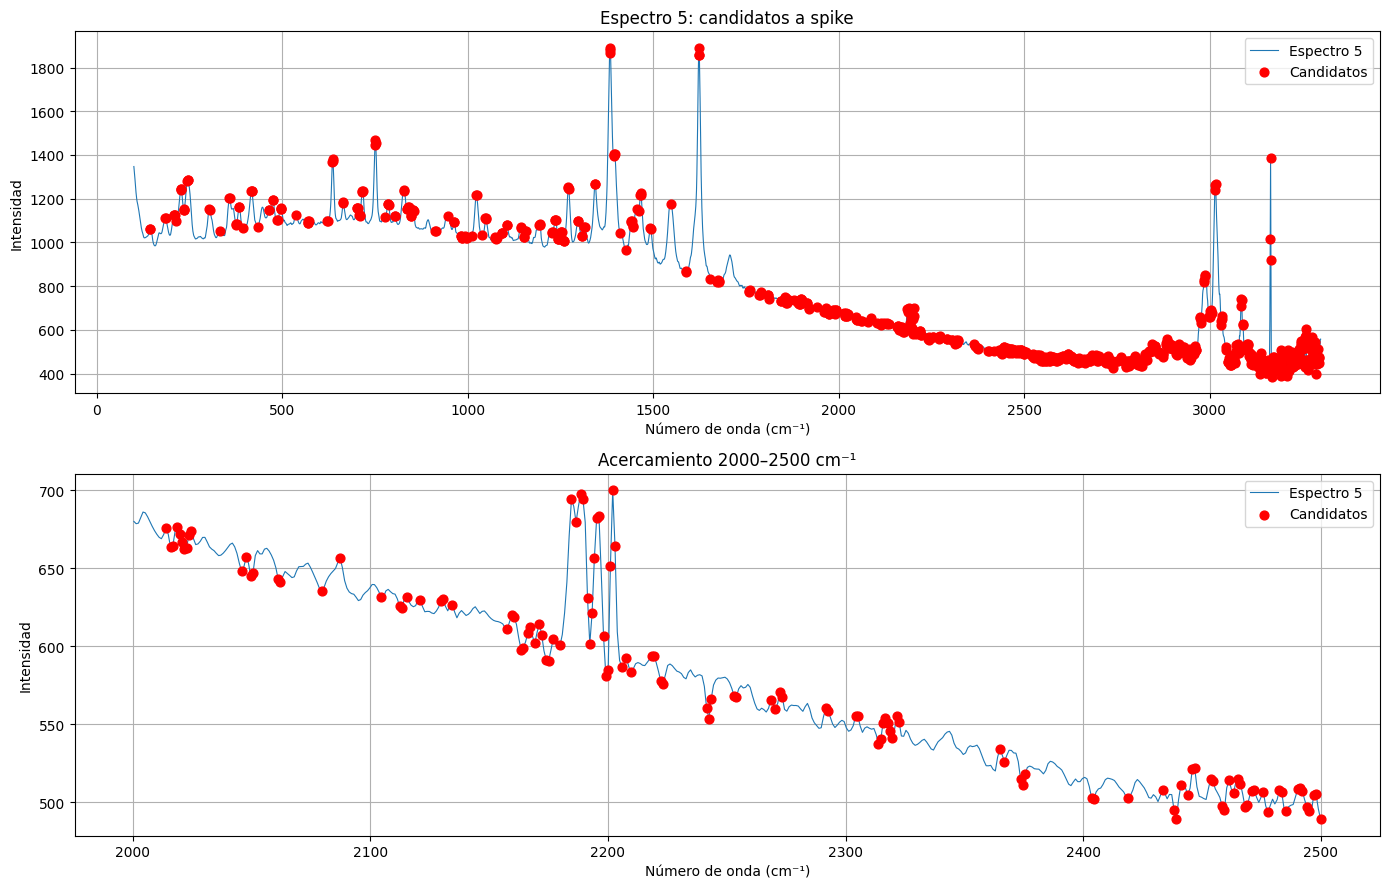

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 9))

# (a) Espectro completo
ejes[0].plot(WD, esp5, lw=0.8, label="Espectro 5")
ejes[0].scatter(WD[idx5], esp5[idx5], color="red", s=40, zorder=3, label="Candidatos")
ejes[0].set_title("Espectro 5: candidatos a spike")
ejes[0].set_xlabel("Número de onda (cm⁻¹)")
ejes[0].set_ylabel("Intensidad")
ejes[0].legend()
ejes[0].grid(True)

# (b) Acercamiento 2000-2500 cm-1
m = (WD >= 2000) & (WD <= 2500)
ejes[1].plot(WD[m], esp5[m], lw=0.8, label="Espectro 5")
sel = [i for i in idx5 if 2000 <= WD[i] <= 2500]
ejes[1].scatter(WD[sel], esp5[sel], color="red", s=40, zorder=3, label="Candidatos")
ejes[1].set_title("Acercamiento 2000–2500 cm⁻¹")
ejes[1].set_xlabel("Número de onda (cm⁻¹)")
ejes[1].set_ylabel("Intensidad")
ejes[1].legend()
ejes[1].grid(True)

plt.tight_layout()
plt.show()

Sigma robusta del residuo: 0.385
Residuo máximo absoluto:   743.4

Top 12 residuos (ordenados por posición):
 indice  WD (cm-1)  intensidad  residuo
   1579    1622.50      1857.9     83.7
   1580    1623.46      1890.3    116.1
   1581    1624.43      1855.6     81.4
   2180    2202.00       700.1     90.9
   3177    3163.34      1013.7    372.5
   3178    3164.31      1384.5    743.4
   3179    3165.27       920.4    279.2
   3181    3167.20       385.6    -82.6
   3273    3255.91       432.2    -87.2
   3276    3258.80       602.6    109.3
   3277    3259.77       574.7     81.4
   3298    3280.02       444.7    -90.5


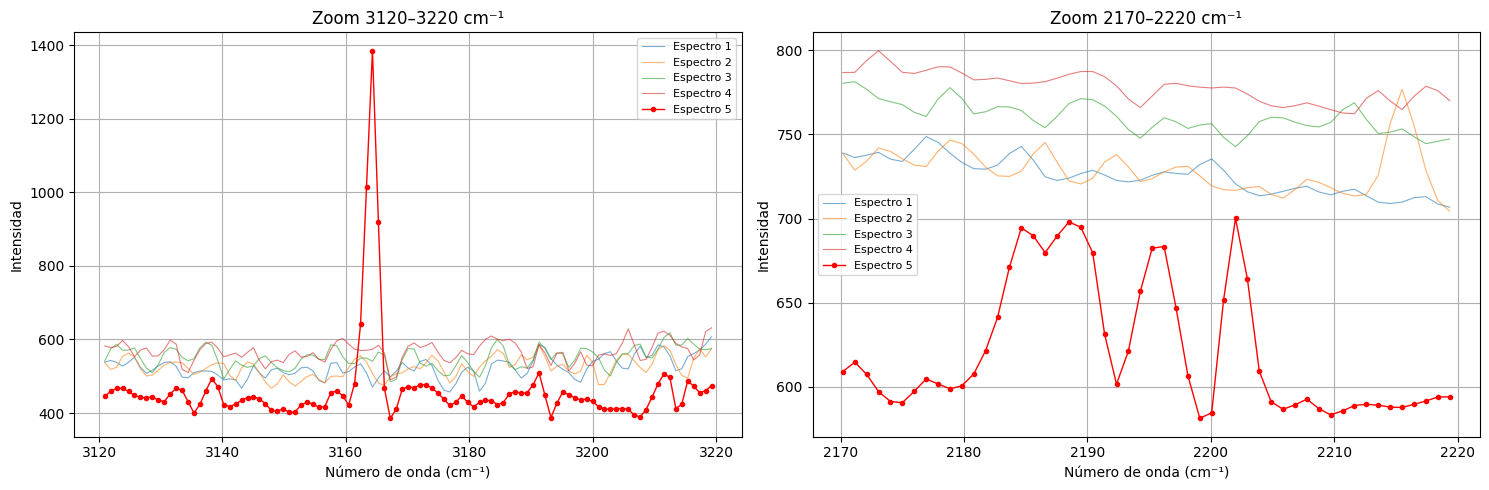

In [ ]:
# ==================================================
# DIAGNÓSTICO (bloque temporal, NO va en el notebook final)
# ==================================================
residuo5 = esp5 - base5
sigma5 = 1.4826 * np.median(np.abs(residuo5 - np.median(residuo5)))

print(f"Sigma robusta del residuo: {sigma5:.3f}")
print(f"Residuo máximo absoluto:   {np.max(np.abs(residuo5)):.1f}")

# Los 12 puntos con mayor |residuo|
top = np.sort(np.argsort(-np.abs(residuo5))[:12])
print("\nTop 12 residuos (ordenados por posición):")
print(pd.DataFrame({
    "indice": top,
    "WD (cm-1)": WD[top].round(2),
    "intensidad": esp5[top].round(1),
    "residuo": residuo5[top].round(1),
}).to_string(index=False))

# Zoom a las dos zonas sospechosas, con los espectros 1-4 como comparación
zonas = [(3120, 3220), (2170, 2220)]
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (a, b) in zip(ejes, zonas):
    m = (WD >= a) & (WD <= b)
    for k in range(4):
        ax.plot(WD[m], X_espectros[k][m], lw=0.8, alpha=0.6, label=f"Espectro {k+1}")
    ax.plot(WD[m], esp5[m], "o-", color="red", ms=3, lw=1, label="Espectro 5")
    ax.set_title(f"Zoom {a}–{b} cm⁻¹")
    ax.set_xlabel("Número de onda (cm⁻¹)")
    ax.set_ylabel("Intensidad")
    ax.legend(fontsize=8)
    ax.grid(True)
plt.tight_layout()
plt.show()

## Al encontrar que existen posibles espectros que cuentan con señales contaminadas ¿Cuales espectros son los contaminados?

In [ ]:
base_todos = median_filter(X_espectros, size=(1, 7), mode="nearest")
res_pos = np.clip(X_espectros - base_todos, 0, None)

# Tabla para encontrar los espectros con picos tan grandes
filas = np.arange(X_espectros.shape[0])
max_res = res_pos.max(axis=1)
pos_max = res_pos.argmax(axis=1)
inten_local = base_todos[filas, pos_max]

resumen = pd.DataFrame({
    "espectro": filas + 1,
    "max_residuo": max_res.round(1),
    "WD (cm-1)": WD[pos_max].round(1),
    "intensidad_local": inten_local.round(1),
    "relativo": (max_res / inten_local).round(2),
}).sort_values("max_residuo", ascending=False)

print("Top 15 espectros por residuo positivo máximo:")
print(resumen.head(15).to_string(index=False))

Top 15 espectros por residuo positivo máximo:
 espectro  max_residuo  WD (cm-1)  intensidad_local  relativo
      428       3421.6     3196.1            1732.7      1.97
      439       1311.6     3240.5             417.3      3.14
      105       1022.3     3270.4             486.5      2.10
      518        928.5     3292.6             210.2      4.42
      361        857.2     3270.4             176.1      4.87
        5        743.4     3164.3             641.2      1.16
       63        689.9     3264.6             354.8      1.94
      377        681.7     3099.7             501.7      1.36
      435        661.1     3264.6             345.6      1.91
      315        655.9     3202.9             119.8      5.47
      354        653.6     3264.6             202.6      3.23
       57        647.7     3264.6             380.5      1.70
       55        643.9     3264.6             538.8      1.20
      433        637.3     3264.6             359.3      1.77
      369        636.6  

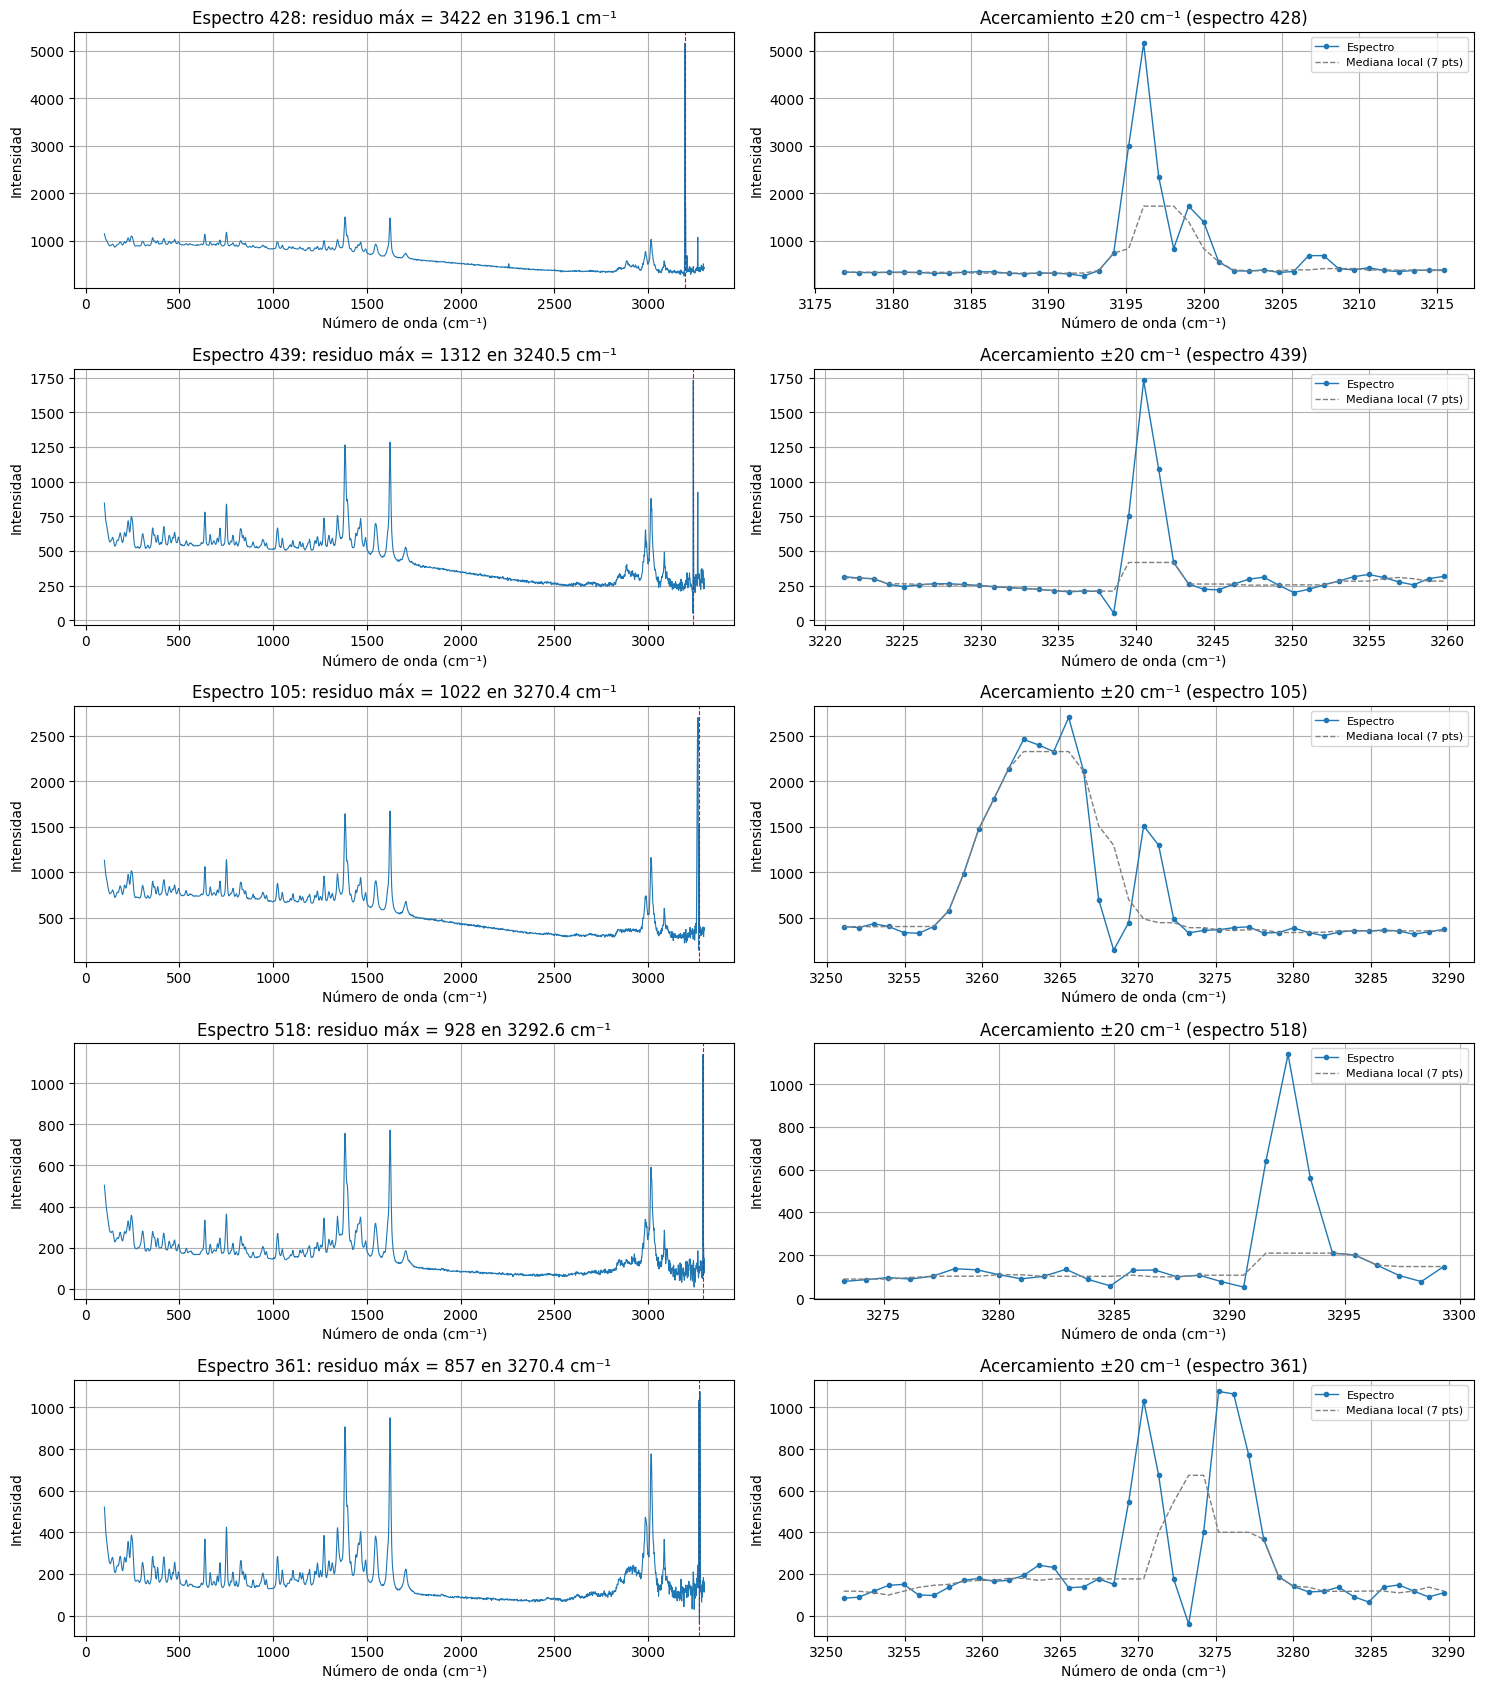

In [ ]:
# DIAGNÓSTICO 3
# Vista gráfica del top 5 de residuos positivos

top5 = resumen.head(5)

fig, ejes = plt.subplots(5, 2, figsize=(15, 17))

for fila, (_, r) in enumerate(top5.iterrows()):
    k = int(r["espectro"]) - 1          # índice en X_espectros
    wd0 = r["WD (cm-1)"]
    esp = X_espectros[k]

    # Izquierda: espectro completo
    ax = ejes[fila, 0]
    ax.plot(WD, esp, lw=0.8)
    ax.axvline(wd0, color="red", ls="--", lw=0.8)
    ax.set_title(f"Espectro {k+1}: residuo máx = {r['max_residuo']:.0f} en {wd0:.1f} cm⁻¹")
    ax.set_xlabel("Número de onda (cm⁻¹)")
    ax.set_ylabel("Intensidad")
    ax.grid(True)

    # Derecha: acercamiento con la mediana local
    ax = ejes[fila, 1]
    m = (WD >= wd0 - 20) & (WD <= wd0 + 20)
    ax.plot(WD[m], esp[m], "o-", ms=3, lw=1, label="Espectro")
    ax.plot(WD[m], base_todos[k][m], "--", color="gray", lw=1, label="Mediana local (7 pts)")
    ax.set_title(f"Acercamiento ±20 cm⁻¹ (espectro {k+1})")
    ax.set_xlabel("Número de onda (cm⁻¹)")
    ax.set_ylabel("Intensidad")
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Etiquetas de Laboratorios de cada espectro y repetición de posiciones
etiquetas = np.repeat(list("ABCDEFGH"), 75)       # supone orden contiguo A..H
resumen["lab"] = etiquetas[resumen["espectro"].values - 1]

top15 = resumen.head(15)
print(top15[["espectro", "lab", "max_residuo", "WD (cm-1)"]].to_string(index=False))
print("\nPosiciones repetidas en el top 15:")
print(top15["WD (cm-1)"].value_counts().head(5))

 espectro lab  max_residuo  WD (cm-1)
      428   F       3421.6     3196.1
      439   F       1311.6     3240.5
      105   B       1022.3     3270.4
      518   G        928.5     3292.6
      361   E        857.2     3270.4
        5   A        743.4     3164.3
       63   A        689.9     3264.6
      377   F        681.7     3099.7
      435   F        661.1     3264.6
      315   E        655.9     3202.9
      354   E        653.6     3264.6
       57   A        647.7     3264.6
       55   A        643.9     3264.6
      433   F        637.3     3264.6
      369   E        636.6     3264.6

Posiciones repetidas en el top 15:
WD (cm-1)
3264.6    7
3270.4    2
3240.5    1
3196.1    1
3292.6    1
Name: count, dtype: int64


## Visualización de los espectros con enormes cambios en su intensidad

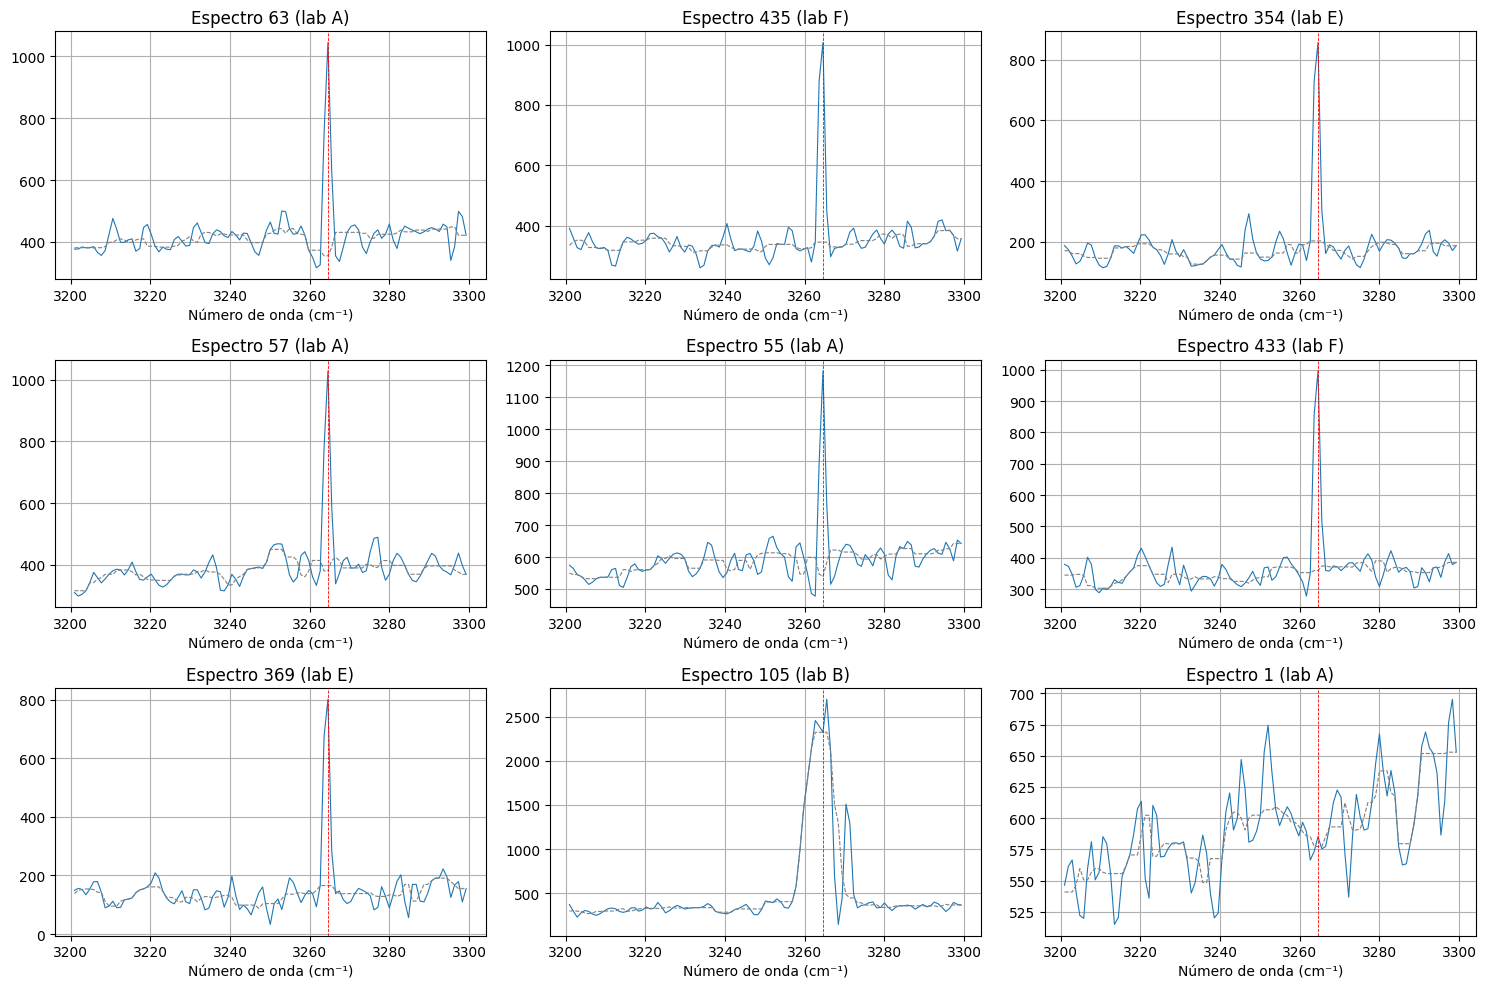

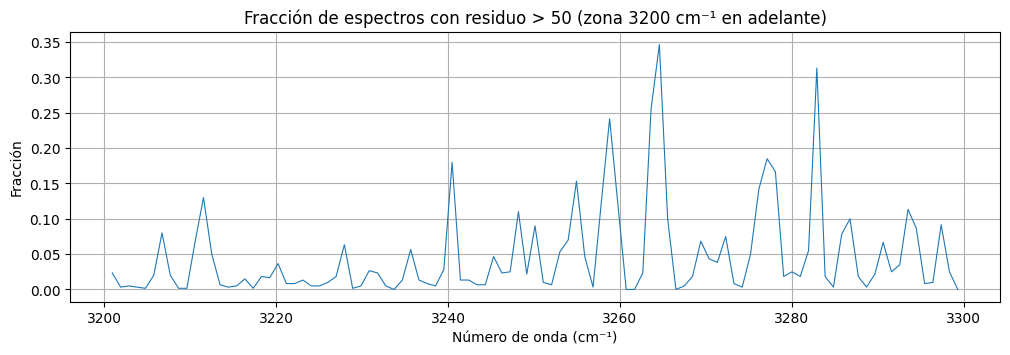

In [ ]:
# Zona sospechosa: espectros con máximo en 3264.6 y 3270.4, más el espectro 1 de control
zona = (WD >= 3200) & (WD <= WD.max())
lista = [63, 435, 354, 57, 55, 433, 369, 105]

fig, ejes = plt.subplots(3, 3, figsize=(15, 10))
for ax, e in zip(ejes.ravel(), lista + [1]):
    k = e - 1
    ax.plot(WD[zona], X_espectros[k][zona], lw=0.8)
    ax.plot(WD[zona], base_todos[k][zona], "--", color="gray", lw=0.8)
    ax.axvline(3264.6, color="red", ls="--", lw=0.6)
    ax.set_title(f"Espectro {e} (lab {etiquetas[k]})")
    ax.set_xlabel("Número de onda (cm⁻¹)")
    ax.grid(True)
plt.tight_layout()
plt.show()

frac = (res_pos > 50).mean(axis=0)

plt.figure(figsize=(12, 3.5))
plt.plot(WD[zona], frac[zona], lw=0.8)
plt.title("Fracción de espectros con residuo > 50 (zona 3200 cm⁻¹ en adelante)")
plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Fracción")
plt.grid(True)
plt.show()

In [ ]:
def ancho_evento(res, idx, frac_pico=0.2):
    corte = frac_pico * res[idx]
    izq = idx
    while izq > 0 and res[izq - 1] > corte:
        izq -= 1
    der = idx
    while der < len(res) - 1 and res[der + 1] > corte:
        der += 1
    return der - izq + 1

filas = []
for _, r in top15.iterrows():
    k = int(r["espectro"]) - 1
    idx = int(np.argmin(np.abs(WD - r["WD (cm-1)"])))
    filas.append({
        "espectro": k + 1,
        "lab": etiquetas[k],
        "WD (cm-1)": round(WD[idx], 1),
        "max_residuo": round(res_pos[k, idx], 1),
        "ancho_puntos": ancho_evento(res_pos[k], idx),
        "frac_espectros_misma_pos": round(frac[idx], 3),
    })

print(pd.DataFrame(filas).to_string(index=False))

 espectro lab  WD (cm-1)  max_residuo  ancho_puntos  frac_espectros_misma_pos
      428   F     3196.1       3421.6             2                     0.003
      439   F     3240.5       1311.6             3                     0.180
      105   B     3270.4       1022.3             2                     0.043
      518   G     3292.6        928.5             3                     0.035
      361   E     3270.4        857.2             3                     0.043
        5   A     3164.3        743.4             3                     0.005
       63   A     3264.6        689.9             3                     0.347
      377   F     3099.7        681.7             3                     0.007
      435   F     3264.6        661.1             2                     0.347
      315   E     3202.9        655.9             2                     0.005
      354   E     3264.6        653.6             2                     0.347
       57   A     3264.6        647.7             3             

 espectro lab  grupos_detectados  puntos_marcados                                                  posiciones (cm-1)
        5   A                128              204         463.5, 570.5, 571.5, 604.3, 916.7, 981.3, 982.2, 993.8 ...
      428   F                130              213      368.0, 592.7, 593.7, 908.0, 991.9, 1119.2, 1120.1, 1252.2 ...
      315   E                160              294         168.4, 169.4, 170.4, 464.5, 515.6, 603.3, 774.9, 864.6 ...
      377   F                 94              151       463.5, 464.5, 593.7, 861.7, 862.7, 977.4, 1440.3, 1576.2 ...
       63   A                142              226      463.5, 464.5, 774.9, 879.1, 984.2, 1396.9, 1413.3, 1414.2 ...
      105   B                122              208   864.6, 865.6, 1251.3, 1252.2, 1413.3, 1414.2, 1442.2, 1676.5 ...
      361   E                144              247         463.5, 464.5, 581.1, 593.7, 603.3, 604.3, 774.0, 774.9 ...
      439   F                107              168    839.5, 840.

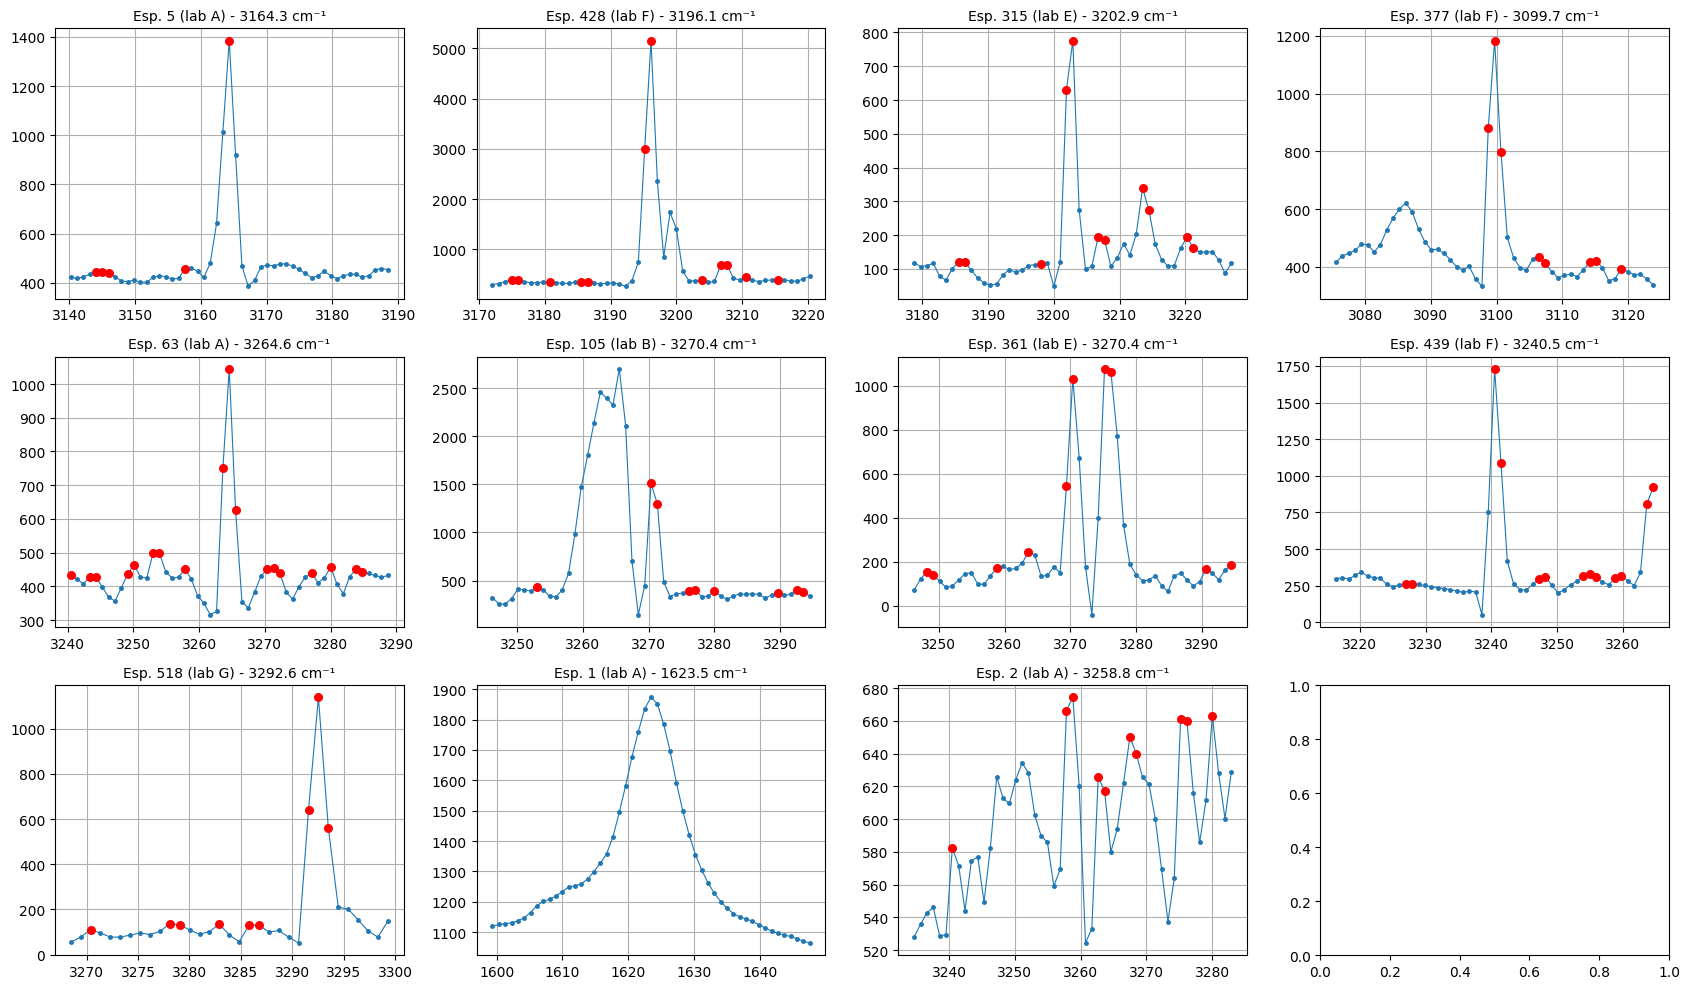


Índice de 3264.6 cm-1: 3282
Fracción con residuo > 50 en ese punto: 0.347
Fracción con residuo > 20 en ese punto: 0.588


In [ ]:

# DETECTOR v2 - PRUEBA (cambia el tamaño de el umbral)

from scipy.ndimage import label

def detectar_spikes_v2(esp, v_corta=7, v_larga=41, k=8, ratio_min=0.7, ancho_max=5):
    med_c = median_filter(esp, size=v_corta, mode="nearest")
    med_l = median_filter(esp, size=v_larga, mode="nearest")
    res = esp - med_c                      # residuo contra base local
    alt = esp - med_l                      # altura sobre base amplia
    ruido = 1.4826 * np.median(np.abs(res - np.median(res)))

    cand = (res > k * ruido) & (alt > 0) & (res / np.where(alt > 0, alt, np.inf) > ratio_min)

    grupos, n = label(cand)
    mascara = np.zeros_like(cand)
    for g in range(1, n + 1):
        pts = np.where(grupos == g)[0]
        if len(pts) <= ancho_max:          # grupos más anchos NO son spike
            mascara[pts] = True
    return mascara, grupos, n

prueba = [5, 428, 315, 377, 63, 105, 361, 439, 518, 1, 2]

filas = []
for e in prueba:
    k_ = e - 1
    masc, grupos, n = detectar_spikes_v2(X_espectros[k_])
    pos = WD[masc]
    filas.append({
        "espectro": e, "lab": etiquetas[k_],
        "grupos_detectados": n,
        "puntos_marcados": int(masc.sum()),
        "posiciones (cm-1)": ", ".join(f"{p:.1f}" for p in pos[:8]) + (" ..." if len(pos) > 8 else ""),
    })
print(pd.DataFrame(filas).to_string(index=False))

# acercamiento a la posición del máximo de cada espectro
fig, ejes = plt.subplots(3, 4, figsize=(17, 10))
for ax, e in zip(ejes.ravel(), prueba):
    k_ = e - 1
    masc, _, _ = detectar_spikes_v2(X_espectros[k_])
    wd0 = resumen.loc[resumen["espectro"] == e, "WD (cm-1)"].values[0]
    m = (WD >= wd0 - 25) & (WD <= wd0 + 25)
    ax.plot(WD[m], X_espectros[k_][m], "o-", ms=2.5, lw=0.8)
    ax.scatter(WD[m & masc], X_espectros[k_][m & masc], color="red", s=30, zorder=3)
    ax.set_title(f"Esp. {e} (lab {etiquetas[k_]}) - {wd0:.1f} cm⁻¹", fontsize=10)
    ax.grid(True)
plt.tight_layout()
plt.show()

# Posición 3264.6
i_fijo = int(np.argmin(np.abs(WD - 3264.6)))
print(f"\nÍndice de 3264.6 cm-1: {i_fijo}")
print("Fracción con residuo > 50 en ese punto:", round(float((res_pos[:, i_fijo] > 50).mean()), 3))
print("Fracción con residuo > 20 en ese punto:", round(float((res_pos[:, i_fijo] > 20).mean()), 3))

## Detector Versión 3

In [ ]:
# DETECTOR v3 - cambia con respecto a la versión 2, que v2 calcula de forma global para todo el espectro aplicando MAD
# Detector v3 en cambio calcula el ruido local usando filtro mediana movil
from scipy.ndimage import label, binary_dilation

def detectar_spikes_v3(esp, v_larga=41, v_ruido=101, k=8, ratio_min=0.7,
                       ancho_max=5, expandir=2):
    med_c = median_filter(esp, size=7, mode="nearest")
    med_l = median_filter(esp, size=v_larga, mode="nearest")
    res = esp - med_c

    # (1) Ruido local: MAD móvil del residuo
    ruido = 1.4826 * median_filter(np.abs(res), size=v_ruido, mode="nearest")
    ruido = np.maximum(ruido, 1e-6)

    # (2) Altura contra los flancos (puntos a 3-6 de distancia, a cada lado)
    n = len(esp)
    izq = np.full(n, -np.inf); der = np.full(n, -np.inf)
    for d in range(3, 7):
        izq[d:]    = np.maximum(izq[d:],    esp[:-d])
        der[:-d]   = np.maximum(der[:-d],   esp[d:])
    sobre_flancos = esp - np.maximum(izq, der)
    alt = esp - med_l

    cand = ((sobre_flancos > k * ruido) & (alt > 0) &
            (sobre_flancos / np.where(alt > 0, alt, np.inf) > ratio_min * 0.5))

    grupos, ng = label(cand)
    mascara = np.zeros(n, dtype=bool)
    for g in range(1, ng + 1):
        pts = np.where(grupos == g)[0]
        if len(pts) <= ancho_max:
            mascara[pts] = True
    mascara = binary_dilation(mascara, iterations=expandir)   # (3) cubrir colas
    return mascara

prueba = [5, 428, 315, 377, 63, 105, 361, 439, 518, 1, 2]
filas = []
for e in prueba:
    masc = detectar_spikes_v3(X_espectros[e - 1])
    grupos, ng = label(masc)
    filas.append({"espectro": e, "lab": etiquetas[e - 1],
                  "grupos": ng, "puntos_marcados": int(masc.sum()),
                  "posiciones (cm-1)": ", ".join(f"{WD[(grupos == g)].mean():.1f}" for g in range(1, min(ng, 6) + 1))
                                         if False else ", ".join(f"{WD[np.where(grupos == g)[0]].mean():.1f}" for g in range(1, min(ng, 6) + 1))})
print(pd.DataFrame(filas).to_string(index=False))

# Control de la posición 3264.6: ¿se destaca frente a puntos vecinos?
print("\nFracción de espectros con residuo > 50 por posición:")
for wd0 in [3240, 3250, 3257, 3264.6, 3272, 3280, 3290]:
    i = int(np.argmin(np.abs(WD - wd0)))
    print(f"  {WD[i]:7.1f} cm-1 -> {(res_pos[:, i] > 50).mean():.3f}")

 espectro lab  grupos  puntos_marcados                        posiciones (cm-1)
        5   A      37              211 168.4, 208.9, 227.3, 278.8, 331.9, 463.0
      428   F      44              249 207.5, 280.8, 331.4, 383.5, 495.3, 553.6
      315   E      30              175 168.9, 208.0, 278.8, 384.4, 515.6, 618.2
      377   F      32              187 208.5, 275.0, 283.2, 554.6, 616.3, 664.1
       63   A      31              174 208.5, 332.4, 383.9, 463.5, 583.1, 600.4
      105   B      33              186 208.0, 269.2, 278.4, 330.9, 463.5, 474.1
      361   E      28              156 208.0, 276.9, 330.9, 383.5, 495.3, 617.3
      439   F      37              210 208.0, 277.9, 331.4, 474.1, 585.9, 599.4
      518   G      29              164 142.4, 168.4, 208.5, 330.4, 581.6, 589.3
        1   A      37              203 208.5, 227.3, 276.9, 333.8, 383.5, 475.1
        2   A      35              198 208.0, 284.1, 383.5, 446.1, 474.1, 495.3

Fracción de espectros con residuo > 50 

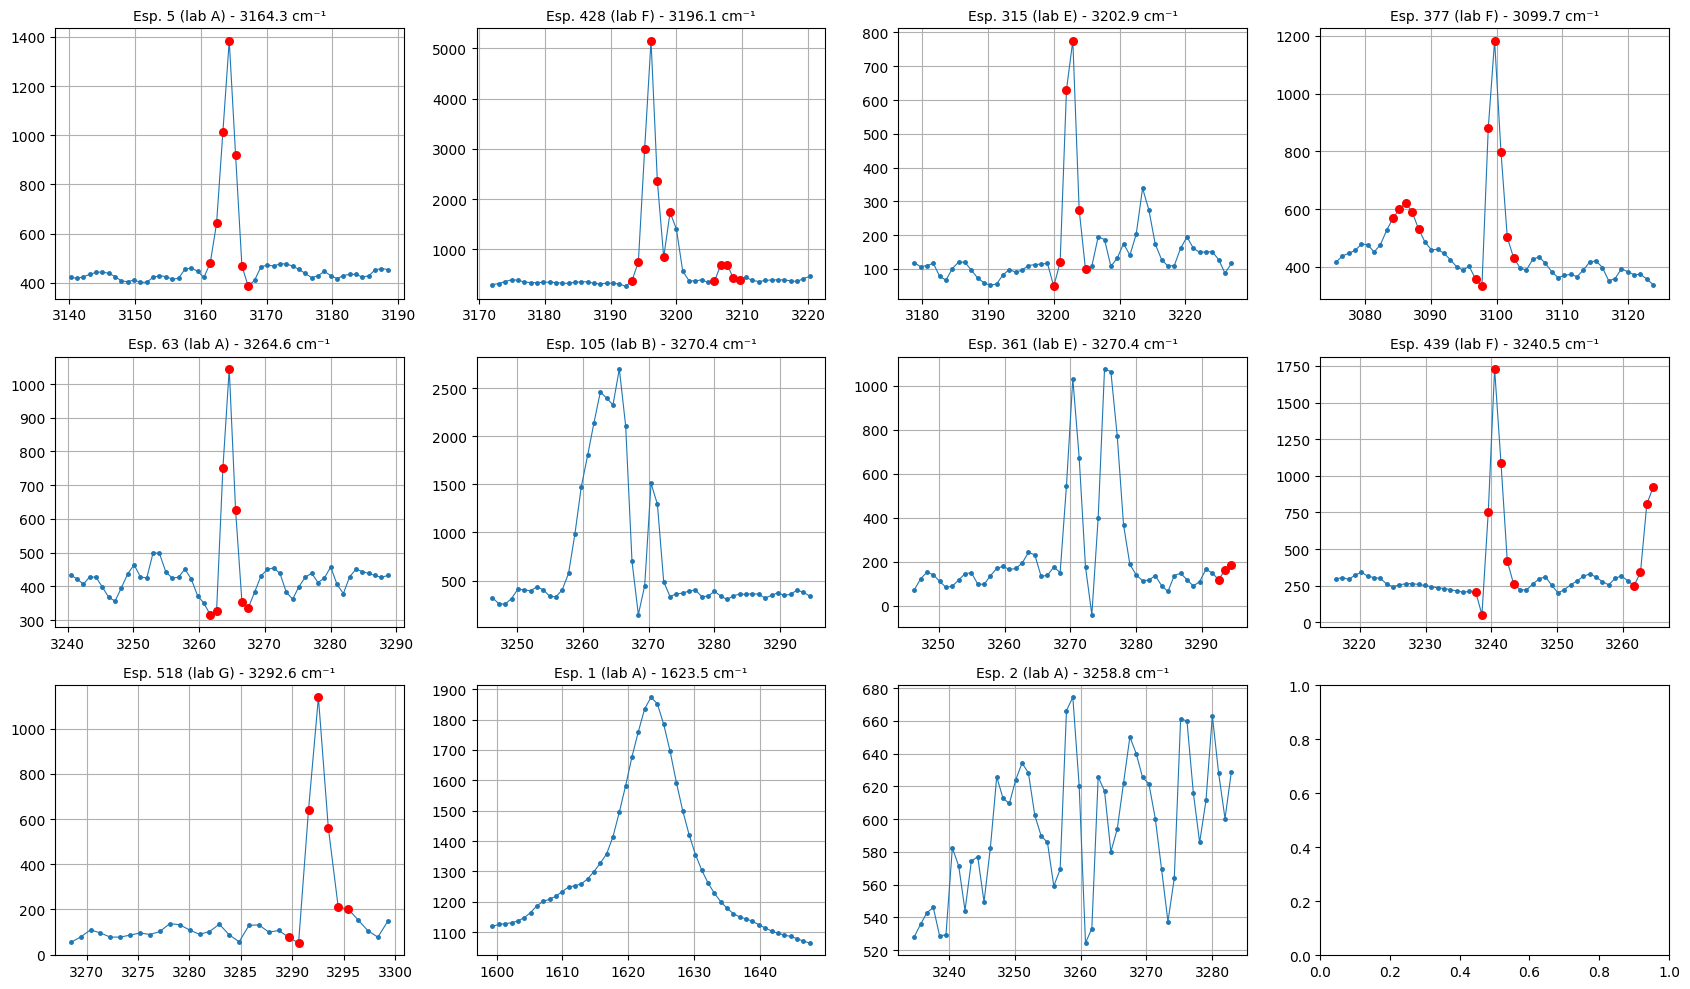

In [ ]:
fig, ejes = plt.subplots(3, 4, figsize=(17, 10))
for ax, e in zip(ejes.ravel(), prueba):
    k_ = e - 1
    masc = detectar_spikes_v3(X_espectros[k_])
    wd0 = resumen.loc[resumen["espectro"] == e, "WD (cm-1)"].values[0]
    m = (WD >= wd0 - 25) & (WD <= wd0 + 25)
    ax.plot(WD[m], X_espectros[k_][m], "o-", ms=2.5, lw=0.8)
    ax.scatter(WD[m & masc], X_espectros[k_][m & masc], color="red", s=30, zorder=3)
    ax.set_title(f"Esp. {e} (lab {etiquetas[k_]}) - {wd0:.1f} cm⁻¹", fontsize=10)
    ax.grid(True)
plt.tight_layout()
plt.show()

## Utilizamos la metodologia que empleo Whitaker-Hayes 2018

 espectro lab  grupos  puntos_marcados                     posiciones (cm-1)
        5   A       4               32         635.1, 1623.5, 2202.0, 3163.3
      428   F       5               40 635.1, 1622.5, 3196.6, 3207.2, 3264.1
      315   E       5               36 635.1, 1622.5, 2201.5, 2213.1, 3202.4
      377   F       2               15                        1623.5, 3099.2
       63   A       3               24                 635.1, 1623.5, 3264.1
      105   B       3               33                 635.1, 1622.5, 3266.5
      361   E       3               25                 635.1, 1622.5, 3270.4
      439   F       4               30         635.1, 1622.5, 3240.0, 3264.1
      518   G       2               18                         635.1, 1623.5
        1   A       1                9                                1623.5
        2   A       1                9                                1623.5


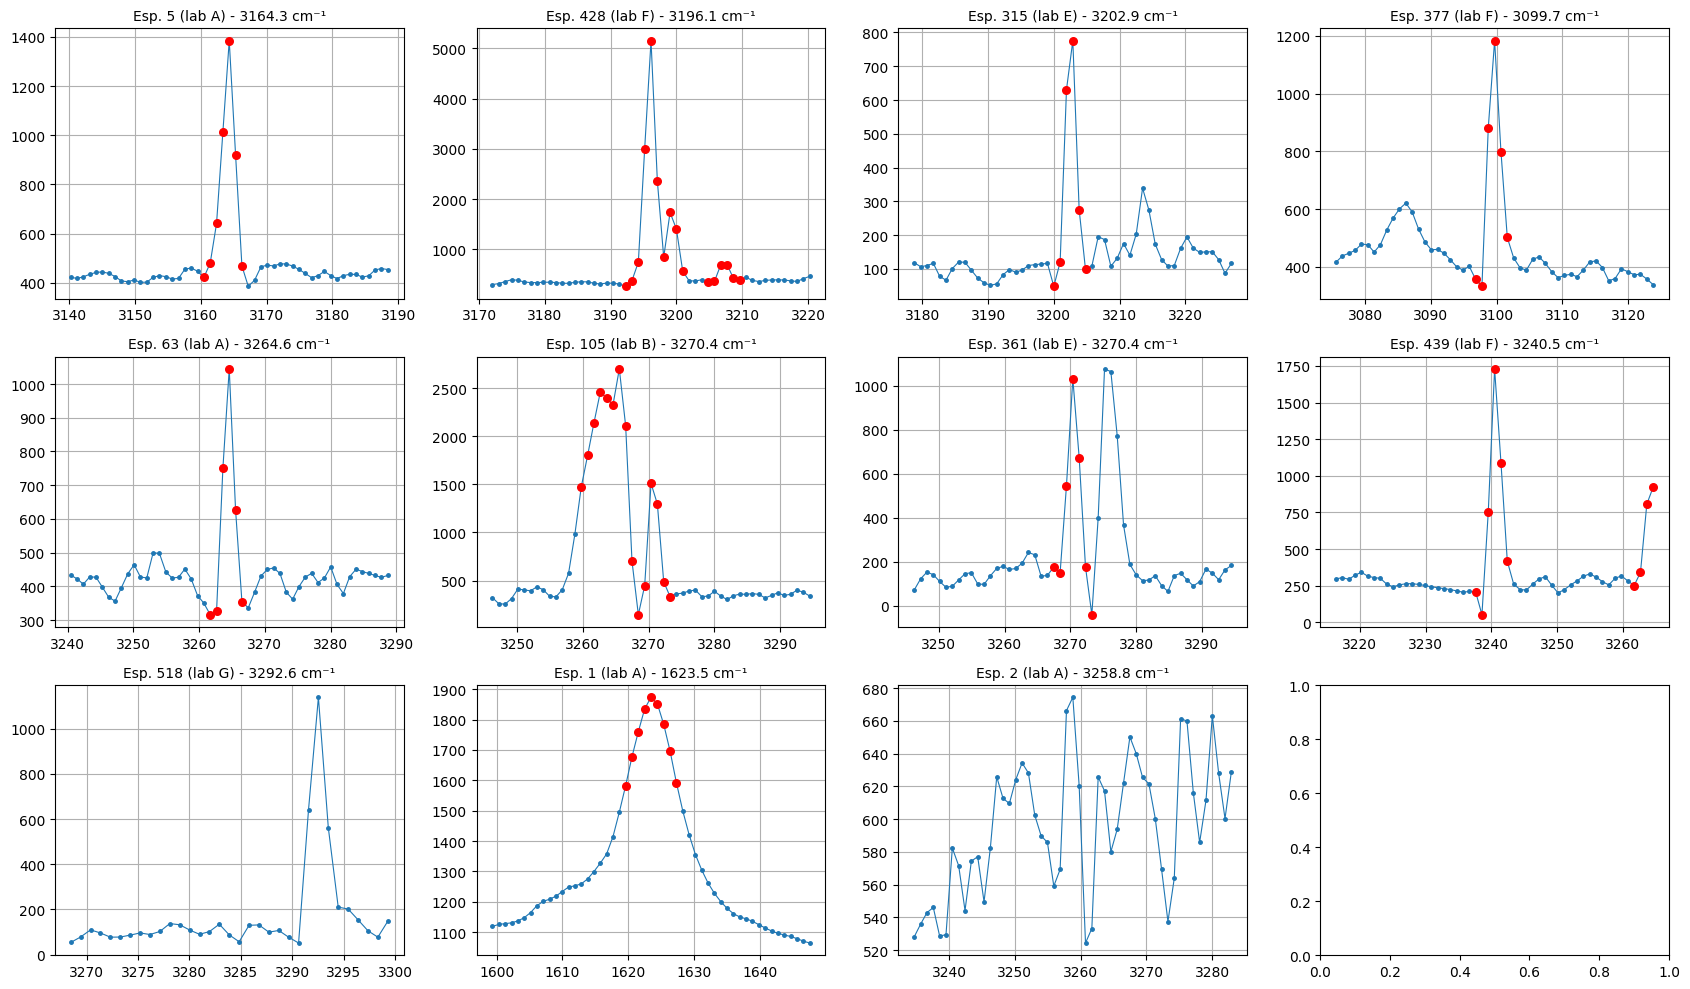

In [ ]:
# Detector utilizado en Whitaker 2018
def detectar_spikes_wh(esp, umbral=8, v_ruido=101, piso_rel=0.3, expandir=2, ancho_max=5):
    d = np.diff(esp)                                   # diferencias consecutivas
    mad_loc = median_filter(np.abs(d - np.median(d)), size=v_ruido, mode="nearest")
    piso = piso_rel * np.median(mad_loc)               # evita ruido ~0 en zonas suaves
    sigma = 1.4826 * np.maximum(mad_loc, piso)
    z = d / sigma                                      # con signo

    # Spike: subida fuerte seguida de bajada fuerte en pocos puntos
    n = len(esp)
    cand = np.zeros(n, dtype=bool)
    sube = np.where(z > umbral)[0]                     # d[i] = esp[i+1]-esp[i]
    for i in sube:
        # buscar caída fuerte en los siguientes ancho_max puntos
        j = np.arange(i + 1, min(i + 1 + ancho_max, n - 1))
        if len(j) and np.any(z[j] < -umbral):
            fin = j[np.argmax(z[j] < -umbral)]         # primera caída fuerte
            cand[i + 1: fin + 1] = True                # puntos entre subida y bajada
    return binary_dilation(cand, iterations=expandir), z

prueba = [5, 428, 315, 377, 63, 105, 361, 439, 518, 1, 2]
filas = []
for e in prueba:
    masc, _ = detectar_spikes_wh(X_espectros[e - 1])
    grupos, ng = label(masc)
    pos = [f"{WD[np.where(grupos == g)[0]].mean():.1f}" for g in range(1, min(ng, 6) + 1)]
    filas.append({"espectro": e, "lab": etiquetas[e - 1], "grupos": ng,
                  "puntos_marcados": int(masc.sum()), "posiciones (cm-1)": ", ".join(pos)})
print(pd.DataFrame(filas).to_string(index=False))

fig, ejes = plt.subplots(3, 4, figsize=(17, 10))
for ax, e in zip(ejes.ravel(), prueba):
    k_ = e - 1
    masc, _ = detectar_spikes_wh(X_espectros[k_])
    wd0 = resumen.loc[resumen["espectro"] == e, "WD (cm-1)"].values[0]
    m = (WD >= wd0 - 25) & (WD <= wd0 + 25)
    ax.plot(WD[m], X_espectros[k_][m], "o-", ms=2.5, lw=0.8)
    ax.scatter(WD[m & masc], X_espectros[k_][m & masc], color="red", s=30, zorder=3)
    ax.set_title(f"Esp. {e} (lab {etiquetas[k_]}) - {wd0:.1f} cm⁻¹", fontsize=10)
    ax.grid(True)
plt.tight_layout()
plt.show()

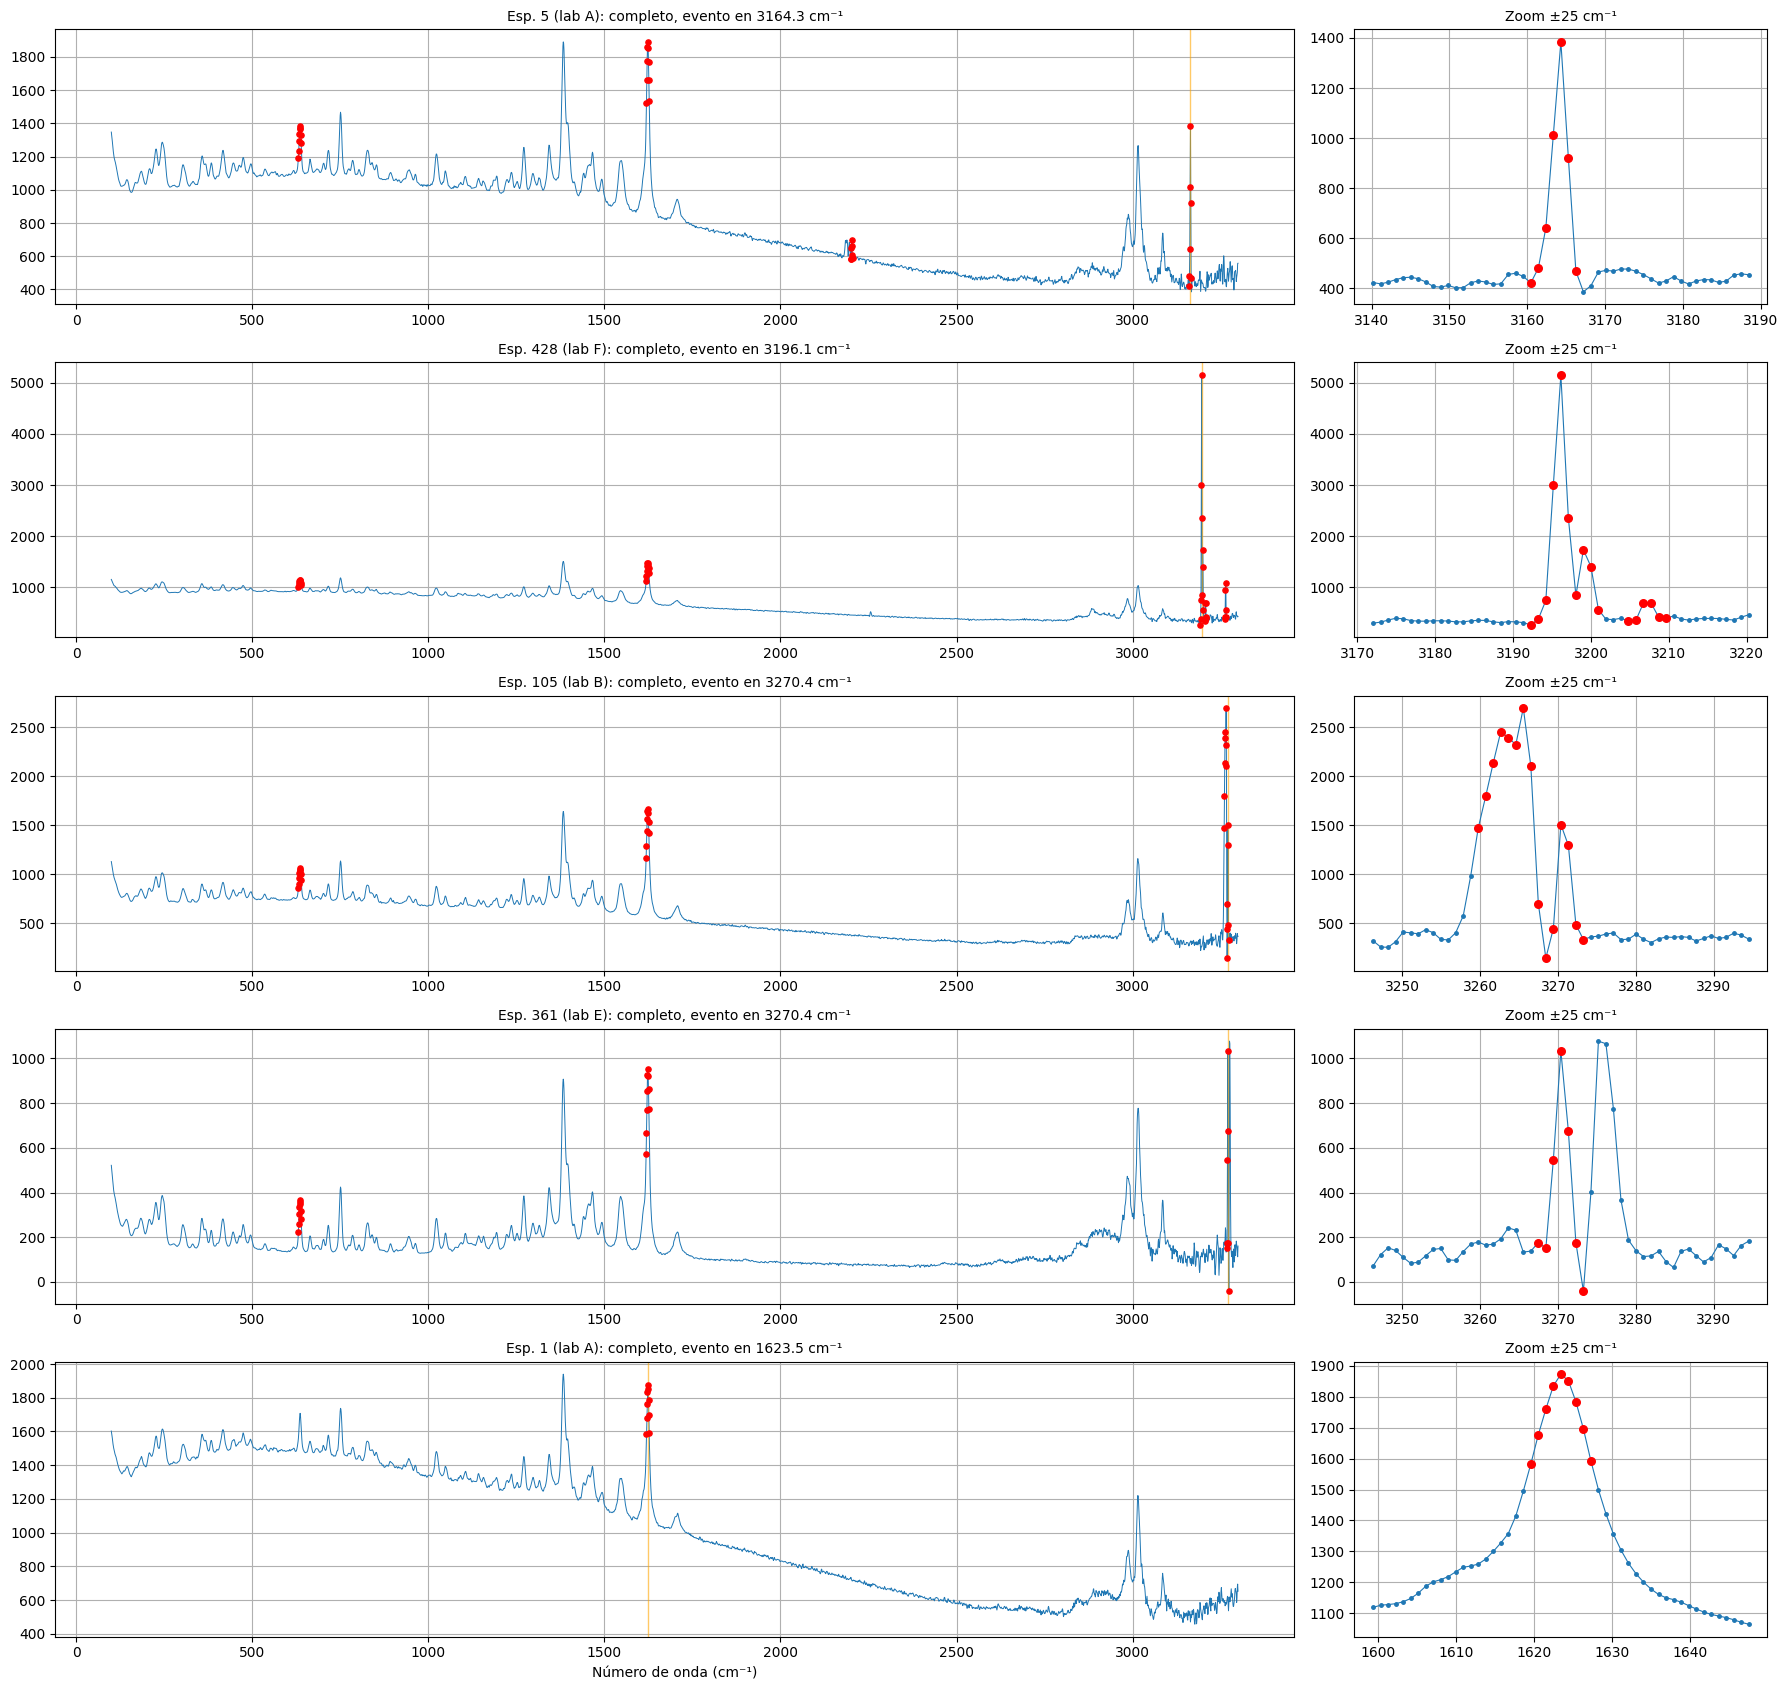

In [ ]:
detector = detectar_spikes_wh          # puedes cambiarlo por otra versión
mostrar = [5, 428, 105, 361, 1]        # <- cambia aquí los 5 espectros

fig, ejes = plt.subplots(len(mostrar), 2, figsize=(18, 3.4 * len(mostrar)),
                         gridspec_kw={"width_ratios": [3, 1]})
for fila, e in zip(ejes, mostrar):
    k_ = e - 1
    masc = detector(X_espectros[k_])
    if isinstance(masc, tuple):         # algunas versiones devuelven (máscara, z)
        masc = masc[0]
    wd0 = resumen.loc[resumen["espectro"] == e, "WD (cm-1)"].values[0]

    fila[0].plot(WD, X_espectros[k_], lw=0.7)
    fila[0].scatter(WD[masc], X_espectros[k_][masc], color="red", s=14, zorder=3)
    fila[0].axvline(wd0, color="orange", lw=1, alpha=0.6)
    fila[0].set_title(f"Esp. {e} (lab {etiquetas[k_]}): completo, evento en {wd0:.1f} cm⁻¹", fontsize=10)
    fila[0].grid(True)

    m = (WD >= wd0 - 25) & (WD <= wd0 + 25)
    fila[1].plot(WD[m], X_espectros[k_][m], "o-", ms=2.5, lw=0.8)
    fila[1].scatter(WD[m & masc], X_espectros[k_][m & masc], color="red", s=30, zorder=3)
    fila[1].set_title("Zoom ±25 cm⁻¹", fontsize=10)
    fila[1].grid(True)

ejes[-1][0].set_xlabel("Número de onda (cm⁻¹)")
plt.tight_layout()
plt.show()

Espectros con al menos 1 punto marcado: 596
Puntos marcados en total: 11305

Posiciones marcadas en >10 % de los espectros:
 WD (cm-1)  frecuencia
     632.2       0.887
     633.2       0.887
     634.2       0.887
     635.1       0.887
     636.1       0.887
     637.1       0.887
     638.0       0.887
     639.0       0.882
    1619.6       0.920
    1620.6       0.952
    1621.5       0.952
    1622.5       0.952
    1623.5       0.952
    1624.4       0.952
    1625.4       0.952
    1626.4       0.952


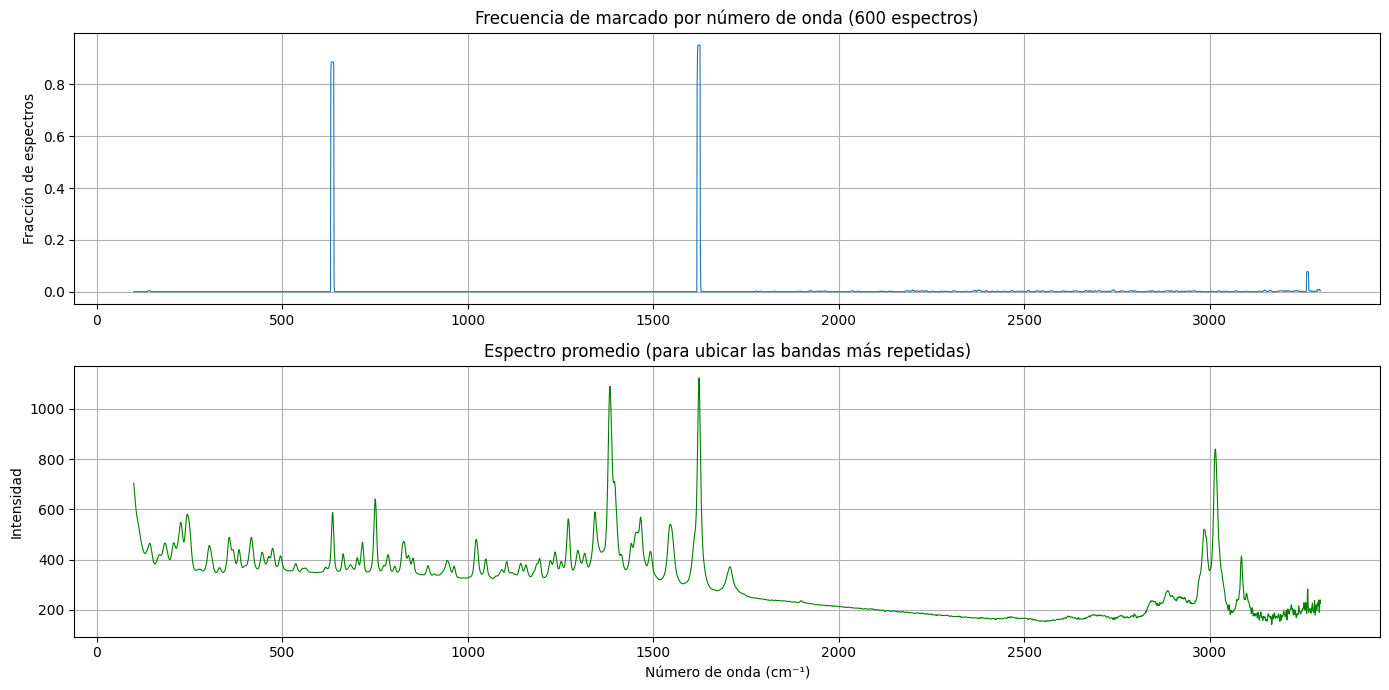

In [ ]:
# Corre WH en los 600 espectros y cuenta cuántas veces se marca cada punto
marcas = np.zeros(X_espectros.shape, dtype=bool)
for k_ in range(X_espectros.shape[0]):
    marcas[k_], _ = detectar_spikes_wh(X_espectros[k_])

frec = marcas.mean(axis=0)            # fracción de espectros marcados en cada WD

print("Espectros con al menos 1 punto marcado:", int(marcas.any(axis=1).sum()))
print("Puntos marcados en total:", int(marcas.sum()))

# Posiciones con frecuencia alta (candidatas a banda real, no a spike)
alta = np.where(frec > 0.85)[0]
print("\nPosiciones marcadas en >10 % de los espectros:")
print(pd.DataFrame({"WD (cm-1)": WD[alta].round(1), "frecuencia": frec[alta].round(3)}).to_string(index=False))

fig, ejes = plt.subplots(2, 1, figsize=(14, 7))
ejes[0].plot(WD, frec, lw=0.8)
ejes[0].set_title("Frecuencia de marcado por número de onda (600 espectros)")
ejes[0].set_ylabel("Fracción de espectros")
ejes[0].grid(True)
ejes[1].plot(WD, X_espectros.mean(axis=0), lw=0.8, color="green")
ejes[1].set_title("Espectro promedio (para ubicar las bandas más repetidas)")
ejes[1].set_xlabel("Número de onda (cm⁻¹)")
ejes[1].set_ylabel("Intensidad")
ejes[1].grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# WH + exclusión de bandas reales
zona_banda = frec > 0.50                       # posiciones que son bandas, no spikes
marcas_f = marcas & ~zona_banda                # quita esas posiciones de toda la matriz

n_con = int(marcas_f.any(axis=1).sum())
print("Espectros con spikes (tras excluir bandas):", n_con, "de", len(marcas_f))
print("Puntos marcados en total:", int(marcas_f.sum()))

# Por laboratorio
por_lab = pd.DataFrame({"lab": etiquetas, "con_spike": marcas_f.any(axis=1),
                        "puntos": marcas_f.sum(axis=1)})
print("\nPor laboratorio:")
print(por_lab.groupby("lab").agg(espectros_con_spike=("con_spike", "sum"),
                                 puntos_totales=("puntos", "sum"),
                                 max_puntos_en_un_espectro=("puntos", "max")).to_string())

# Grupos por espectro: ¿cuántos eventos tiene cada uno?
n_grupos = np.array([label(m)[1] for m in marcas_f])
print("\nDistribución de eventos por espectro:")
print(pd.Series(n_grupos).value_counts().sort_index().to_string())

# Casos pendientes
for e in [1, 2, 5, 105, 361, 428, 518]:
    g, ng = label(marcas_f[e - 1])
    pos = [f"{WD[np.where(g == i)[0]].mean():.1f}" for i in range(1, ng + 1)]
    print(f"Espectro {e} (lab {etiquetas[e-1]}): {ng} eventos -> {', '.join(pos) if pos else 'ninguno'}")

# Espectros con más puntos marcados (revisión: ¿muy dañados o estructura ancha?)
top = por_lab.assign(espectro=np.arange(1, 601)).sort_values("puntos", ascending=False).head(10)
print("\nTop 10 por puntos marcados:")
print(top[["espectro", "lab", "puntos"]].to_string(index=False))

Espectros con spikes (tras excluir bandas): 253 de 600
Puntos marcados en total: 1522

Por laboratorio:
     espectros_con_spike  puntos_totales  max_puntos_en_un_espectro
lab                                                                
A                     50             311                         16
B                     34             213                         24
C                     15             123                         20
D                     14              90                         13
E                     21             145                         25
F                     41             289                         22
G                     52             167                         13
H                     26             184                         13

Distribución de eventos por espectro:
0    347
1    193
2     47
3     12
4      1
Espectro 1 (lab A): 1 eventos -> 1627.3
Espectro 2 (lab A): 1 eventos -> 1627.3
Espectro 5 (lab A): 3 eventos -> 1627.3, 2202.0, 316

## Filtro que mejores resultados se obtuvieron

Espectros con marcas tras ensanchar: 164


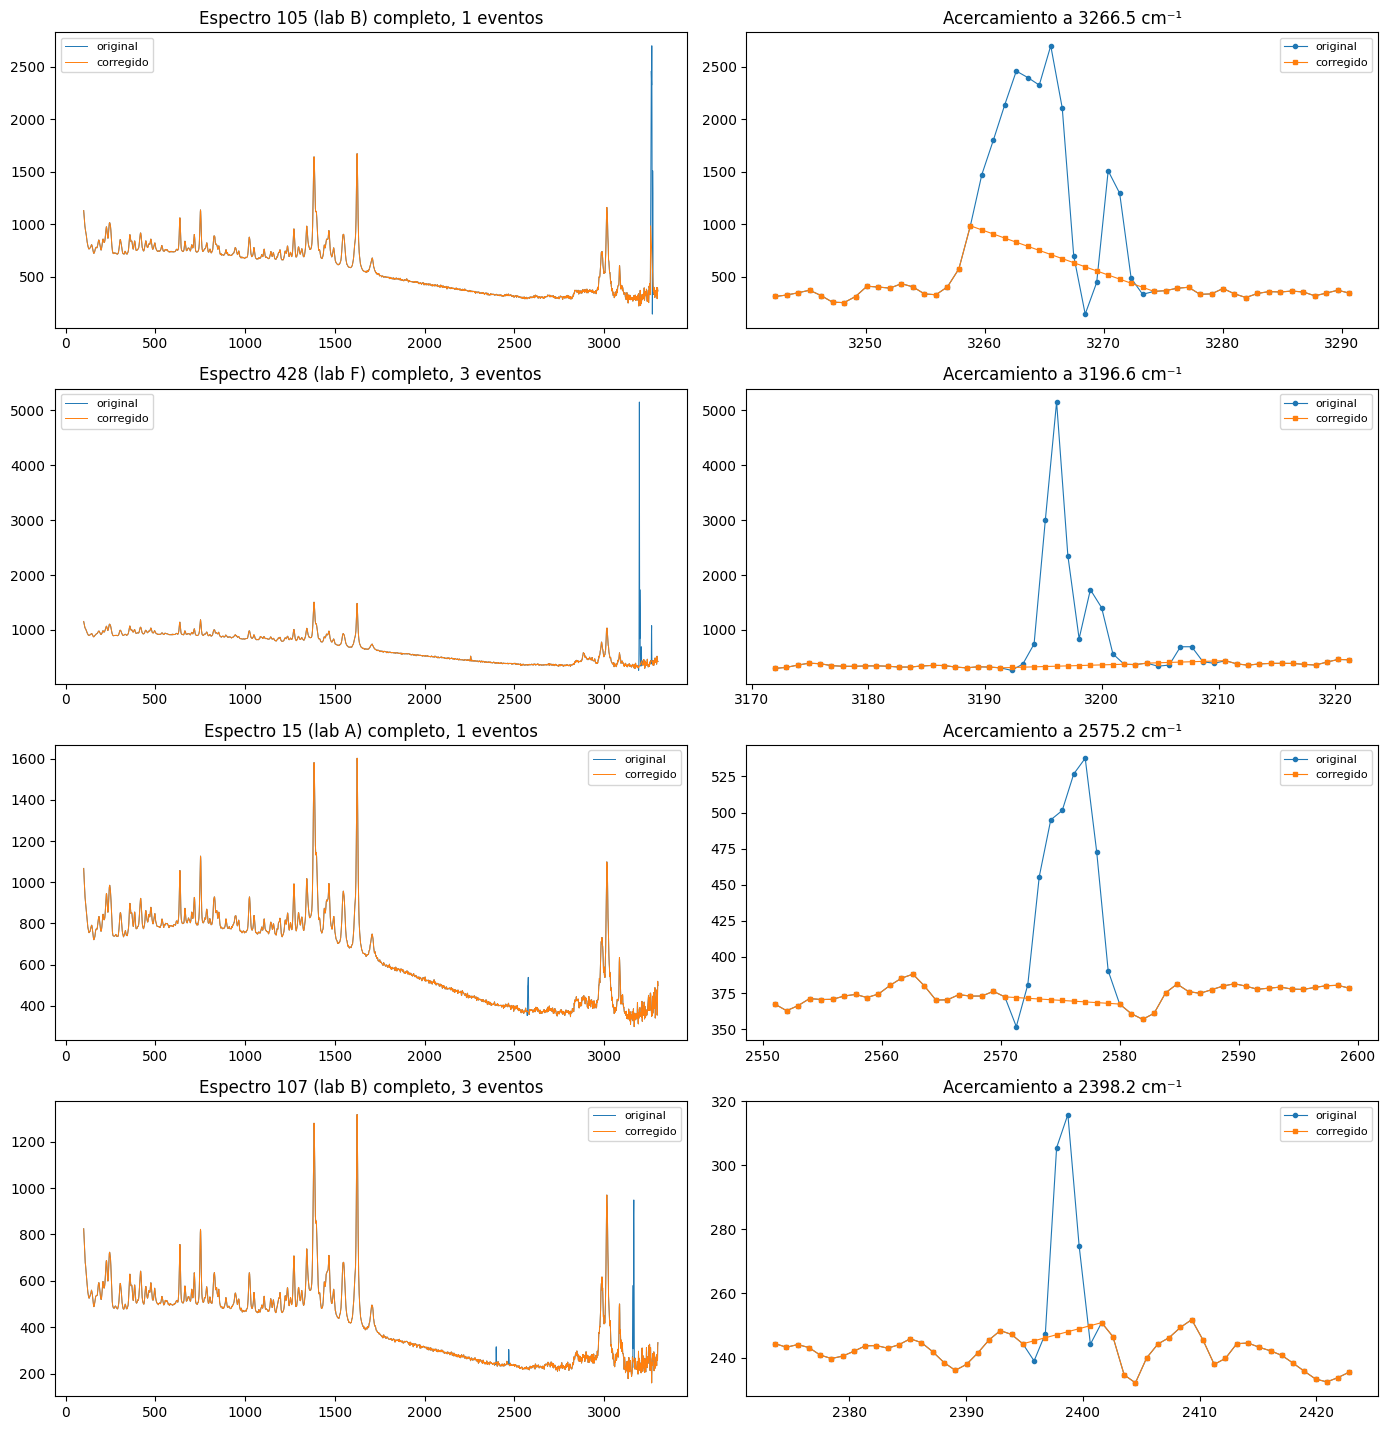

In [ ]:
# DETECTOR + CORRECCIÓN (prueba en pocos espectros)

zona_banda = binary_dilation(frec > 0.50, iterations=5)
marcas_f = marcas & ~zona_banda


def corregir_spikes(esp, mascara):
    out = esp.copy()
    idx = np.arange(len(esp))
    out[mascara] = np.interp(idx[mascara], idx[~mascara], esp[~mascara])
    return out

print("Espectros con marcas tras ensanchar:", int(marcas_f.any(axis=1).sum()))

# 3) Antes/después en espectros de prueba
casos = [105, 428, 15, 107]
fig, ejes = plt.subplots(len(casos), 2, figsize=(14, 3.6 * len(casos)))
for fila, e in enumerate(casos):
    k = e - 1
    corr = corregir_spikes(X_espectros[k], marcas_f[k])
    g, ng = label(marcas_f[k])
    centro = WD[np.where(g == 1)[0]].mean() if ng else WD[1600]
    m = (WD >= centro - 25) & (WD <= centro + 25)
    ejes[fila, 0].plot(WD, X_espectros[k], lw=0.7, label="original")
    ejes[fila, 0].plot(WD, corr, lw=0.7, label="corregido")
    ejes[fila, 0].set_title(f"Espectro {e} (lab {etiquetas[k]}) completo, {ng} eventos")
    ejes[fila, 0].legend(fontsize=8)
    ejes[fila, 1].plot(WD[m], X_espectros[k][m], "o-", ms=3, lw=0.8, label="original")
    ejes[fila, 1].plot(WD[m], corr[m], "s-", ms=3, lw=0.8, label="corregido")
    ejes[fila, 1].set_title(f"Acercamiento a {centro:.1f} cm⁻¹")
    ejes[fila, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Eventos que pasan a revisión manual: 16
 espectro lab     WD  n_puntos
       27   A 3230.8        13
       41   A 3216.9        12
       85   B 2362.5        10
       91   B 2882.8        11
      105   B 3266.5        15
      107   B 3163.3        11
      123   B 2311.9        11
      349   E 2941.1        10
      399   F 2738.6        12
      428   F 3196.6        10
      433   F 3192.8        10
      466   G 2228.5        10
      467   G 1893.4        11
      472   G 3186.5        11
      509   G 2376.5        13
      570   H 1942.1        10

Puntos modificados: 1198

Percentiles del exceso en 3264.6 (50, 75, 90, 95): [ 34.3  89.2 155.8 591.4]
Percentiles del exceso en 3280.0 (control):       [-19.6  13.   40.6  55.3]
Exceso > 50: 257 espectros; de ellos corregidos: 46
Exceso > 100: 124 espectros; de ellos corregidos: 45
Exceso > 200: 57 espectros; de ellos corregidos: 45


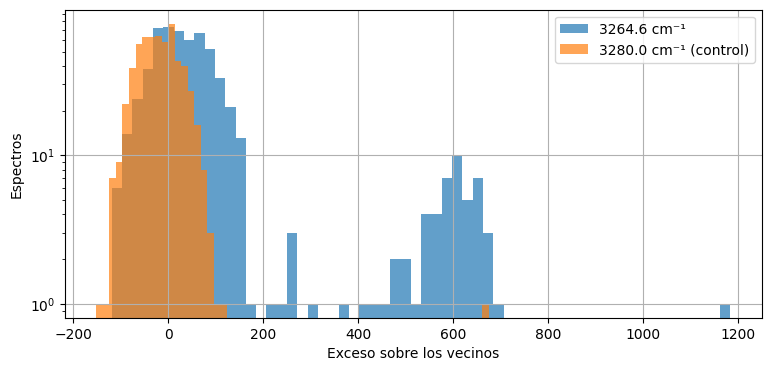

Espectro 105: puntos en marcas_f = 15, en marcas_ok = 0
Espectro 361: puntos en marcas_f = 7, en marcas_ok = 7


In [ ]:
ANCHO_MAX_EVENTO = 9

marcas_ok = marcas_f.copy()
revision = []
for k in range(600):
    g, ng = label(marcas_f[k])
    for i in range(1, ng + 1):
        p = np.where(g == i)[0]
        if len(p) > ANCHO_MAX_EVENTO:
            marcas_ok[k, p] = False
            revision.append((k + 1, etiquetas[k], round(WD[p].mean(), 1), len(p)))

print("Eventos que pasan a revisión manual:", len(revision))
print(pd.DataFrame(revision, columns=["espectro", "lab", "WD", "n_puntos"]).to_string(index=False))

# X_sin_spikes se recalcula a partir de X_espectros (el original no se toca)
X_sin_spikes = np.array([corregir_spikes(X_espectros[k], marcas_ok[k]) for k in range(600)])
print("\nPuntos modificados:", int((X_sin_spikes != X_espectros).sum()))

# --- Artefacto de 3264.6: exceso sobre los vecinos, en los 600 espectros ---
i0 = int(np.argmin(np.abs(WD - 3264.6)))
vec = np.r_[i0 - 7:i0 - 2, i0 + 3:i0 + 8]
exceso = X_espectros[:, i0] - np.median(X_espectros[:, vec], axis=1)

# Mismo cálculo en un punto de control sin artefacto conocido
ic = int(np.argmin(np.abs(WD - 3280.0)))
vec_c = np.r_[ic - 7:ic - 2, ic + 3:ic + 8]
exceso_c = X_espectros[:, ic] - np.median(X_espectros[:, vec_c], axis=1)

corregido_3264 = marcas_ok[:, i0 - 3:i0 + 4].any(axis=1)
print("\nPercentiles del exceso en 3264.6 (50, 75, 90, 95):", np.percentile(exceso, [50, 75, 90, 95]).round(1))
print("Percentiles del exceso en 3280.0 (control):      ", np.percentile(exceso_c, [50, 75, 90, 95]).round(1))
for u in (50, 100, 200):
    print(f"Exceso > {u}: {int((exceso > u).sum())} espectros; de ellos corregidos: {int(((exceso > u) & corregido_3264).sum())}")

plt.figure(figsize=(9, 4))
plt.hist(exceso, bins=60, alpha=0.7, label="3264.6 cm⁻¹")
plt.hist(exceso_c, bins=60, alpha=0.7, label="3280.0 cm⁻¹ (control)")
plt.yscale("log"); plt.legend(); plt.grid(True)
plt.xlabel("Exceso sobre los vecinos"); plt.ylabel("Espectros")
plt.show()

# --- 361 y 105 ---
for e in (105, 361):
    print(f"Espectro {e}: puntos en marcas_f = {int(marcas_f[e-1].sum())}, en marcas_ok = {int(marcas_ok[e-1].sum())}")

Eventos a revisión manual: 5
 espectro lab     WD  nucleo_pts
       27   A 3230.8           9
       41   A 3216.9           8
      105   B 3266.5          11
      399   F 2738.6           8
      509   G 2376.5           9

Espectros con artefacto 3264.6 corregido: 57
Puntos modificados: 1442
¿Cambió algo fuera de la máscara? False


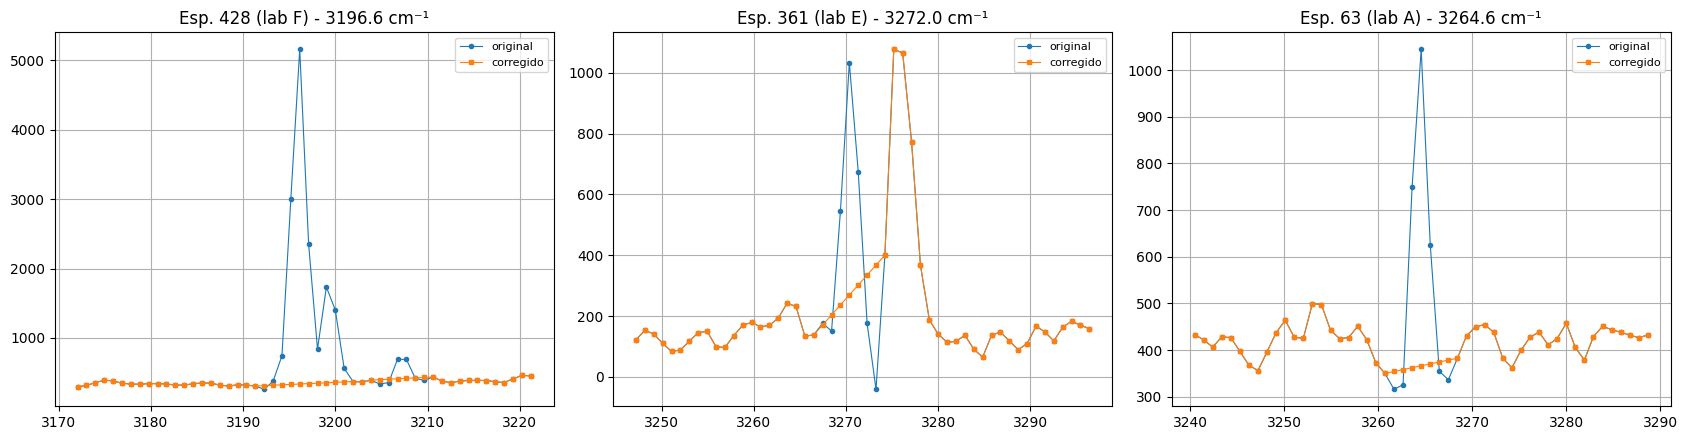

In [ ]:
# (a) Ancho medido SIN dilatación: núcleo = n_puntos - 4
ANCHO_NUCLEO_MAX = 7          # provisional

marcas_ok = marcas_f.copy()
revision = []
for k in range(600):
    g, ng = label(marcas_f[k])
    for i in range(1, ng + 1):
        p = np.where(g == i)[0]
        if len(p) - 4 > ANCHO_NUCLEO_MAX:
            marcas_ok[k, p] = False
            revision.append((k + 1, etiquetas[k], round(WD[p].mean(), 1), len(p) - 4))

# (b) Artefacto fijo en 3264.6: regla específica
i0 = int(np.argmin(np.abs(WD - 3264.6)))
vec = np.r_[i0 - 7:i0 - 2, i0 + 3:i0 + 8]
exceso = X_espectros[:, i0] - np.median(X_espectros[:, vec], axis=1)
con_art = exceso > 200
marcas_ok[con_art, i0 - 3:i0 + 4] = True

print("Eventos a revisión manual:", len(revision))
print(pd.DataFrame(revision, columns=["espectro", "lab", "WD", "nucleo_pts"]).to_string(index=False))
print("\nEspectros con artefacto 3264.6 corregido:", int(con_art.sum()))

X_sin_spikes = np.array([corregir_spikes(X_espectros[k], marcas_ok[k]) for k in range(600)])
print("Puntos modificados:", int((X_sin_spikes != X_espectros).sum()))
print("¿Cambió algo fuera de la máscara?", bool(((X_sin_spikes != X_espectros) & ~marcas_ok).any()))

# Verificación visual: 428, 361 y un caso con artefacto 3264.6
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (e, wd0) in zip(ejes, [(428, 3196.6), (361, 3272.0), (63, 3264.6)]):
    k = e - 1
    m = (WD >= wd0 - 25) & (WD <= wd0 + 25)
    ax.plot(WD[m], X_espectros[k][m], "o-", ms=3, lw=0.8, label="original")
    ax.plot(WD[m], X_sin_spikes[k][m], "s-", ms=3, lw=0.8, label="corregido")
    ax.set_title(f"Esp. {e} (lab {etiquetas[k]}) - {wd0} cm⁻¹")
    ax.legend(fontsize=8); ax.grid(True)
plt.tight_layout(); plt.show()

In [ ]:
# ==================================================
# 7. DETECCIÓN Y CORRECCIÓN DE SPIKES (versión final)
# ==================================================
from scipy.ndimage import median_filter, label, binary_dilation

# Parámetros
UMBRAL_WH, V_RUIDO, PISO_REL = 8, 101, 0.3   # detector Whitaker-Hayes adaptado
EXPANDIR, ANCHO_SUBIDA_BAJADA = 2, 5
FRAC_BANDA, MARGEN_BANDA = 0.50, 5            # exclusión de bandas reales
ANCHO_NUCLEO_MAX = 7                          # eventos más anchos -> revisión manual
EXCESO_ARTEFACTO = 200                        # artefacto fijo en 3264.6 cm-1

def detectar_spikes_wh(esp):
    d = np.diff(esp)
    mad = median_filter(np.abs(d - np.median(d)), size=V_RUIDO, mode="nearest")
    sigma = 1.4826 * np.maximum(mad, PISO_REL * np.median(mad))
    z = d / sigma
    cand = np.zeros(len(esp), dtype=bool)
    for i in np.where(z > UMBRAL_WH)[0]:
        j = np.arange(i + 1, min(i + 1 + ANCHO_SUBIDA_BAJADA, len(esp) - 1))
        if len(j) and np.any(z[j] < -UMBRAL_WH):
            cand[i + 1: j[np.argmax(z[j] < -UMBRAL_WH)] + 1] = True
    return binary_dilation(cand, iterations=EXPANDIR)

def corregir_spikes(esp, mascara):
    out = esp.copy()
    idx = np.arange(len(esp))
    out[mascara] = np.interp(idx[mascara], idx[~mascara], esp[~mascara])
    return out

# 1) Detección en los 600 espectros
marcas = np.array([detectar_spikes_wh(e) for e in X_espectros])

# 2) Excluir bandas reales (marcadas en >50 % de los espectros)
zona_banda = binary_dilation(marcas.mean(axis=0) > FRAC_BANDA, iterations=MARGEN_BANDA)
marcas_f = marcas & ~zona_banda

# 3) Eventos demasiado anchos -> no se interpolan, van a revisión manual
marcas_ok, revision = marcas_f.copy(), []
for k in range(len(marcas_f)):
    g, ng = label(marcas_f[k])
    for i in range(1, ng + 1):
        p = np.where(g == i)[0]
        if len(p) - 2 * EXPANDIR > ANCHO_NUCLEO_MAX:
            marcas_ok[k, p] = False
            revision.append((k + 1, etiquetas[k], round(WD[p].mean(), 1)))

# 4) Artefacto de posición fija en 3264.6 cm-1
i0 = int(np.argmin(np.abs(WD - 3264.6)))
vec = np.r_[i0 - 7:i0 - 2, i0 + 3:i0 + 8]
exceso = X_espectros[:, i0] - np.median(X_espectros[:, vec], axis=1)
marcas_ok[exceso > EXCESO_ARTEFACTO, i0 - 3:i0 + 4] = True

# 5) Corrección (X_espectros no se modifica)
X_sin_spikes = np.array([corregir_spikes(X_espectros[k], marcas_ok[k]) for k in range(len(X_espectros))])

print("Espectros corregidos:", int(marcas_ok.any(axis=1).sum()))
print("Puntos modificados:", int((X_sin_spikes != X_espectros).sum()))
print("Eventos a revisión manual:", revision)

Espectros corregidos: 167
Puntos modificados: 1442
Eventos a revisión manual: [(27, np.str_('A'), np.float64(3230.8)), (41, np.str_('A'), np.float64(3216.9)), (105, np.str_('B'), np.float64(3266.5)), (399, np.str_('F'), np.float64(2738.6)), (509, np.str_('G'), np.float64(2376.5))]


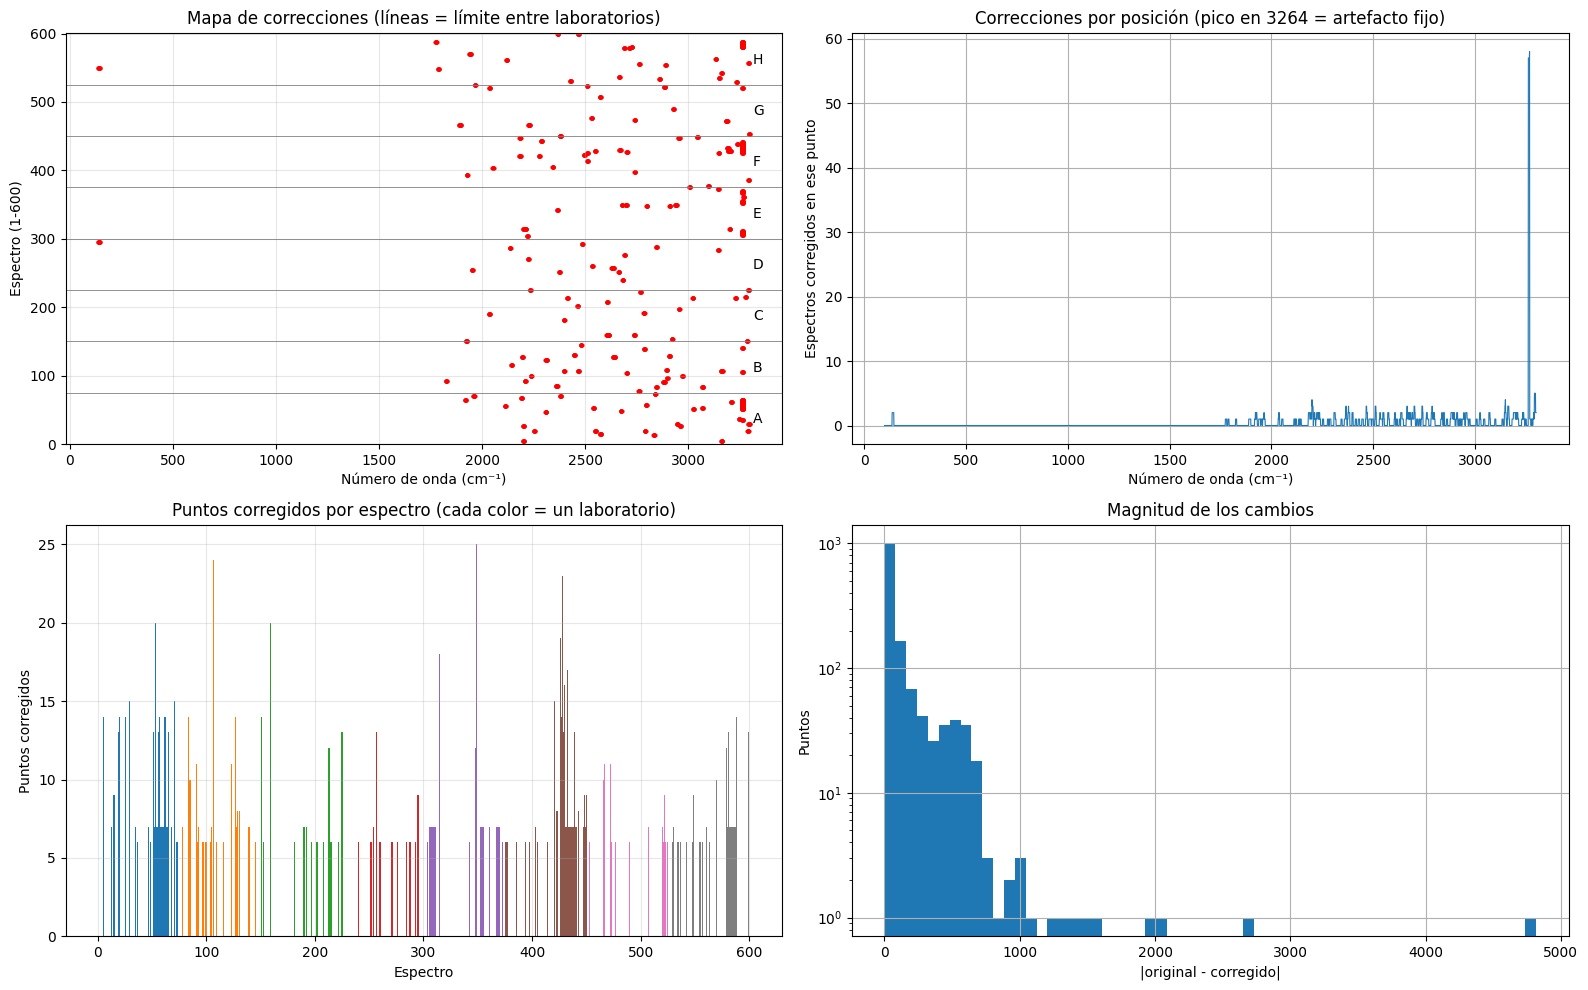

Puntos corregidos por región:
  100-700             :    18 puntos (0.005 % de esa región)
  700-1700 (bandas)   :     0 puntos (0.000 % de esa región)
  1700-3000           :   792 puntos (0.098 % de esa región)
  3000-3300           :   632 puntos (0.339 % de esa región)

Puntos corregidos por laboratorio:
   total  máx. en un espectro
A    290                   20
B    190                   24
C    121                   20
D     89                   13
E    171                   25
F    290                   23
G     97                   11
H    194                   14


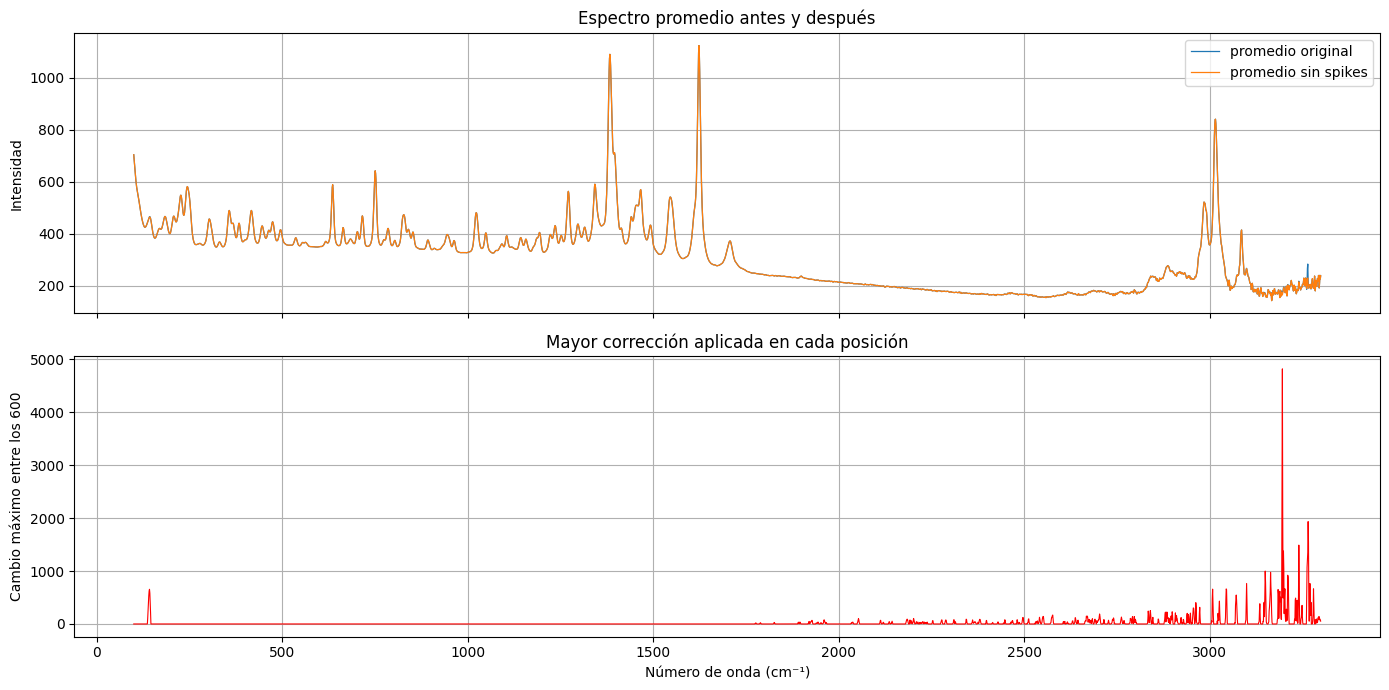

In [ ]:
# ==================================================
# VISUALIZACIÓN DE LO CORREGIDO (diagnóstico; no modifica datos)
# ==================================================
diff = X_espectros - X_sin_spikes                   # distinto de 0 solo donde se corrigió
mod = diff != 0
esp_idx, wd_idx = np.where(mod)

fig, ejes = plt.subplots(2, 2, figsize=(16, 10))

# (a) Mapa de correcciones: cada punto es un valor interpolado
ax = ejes[0, 0]
ax.scatter(WD[wd_idx], esp_idx + 1, s=4, color="red")
for b in range(75, 600, 75):
    ax.axhline(b + 0.5, color="gray", lw=0.6)
for i, lab in enumerate("ABCDEFGH"):
    ax.text(WD.max() + 15, i * 75 + 37, lab, va="center")
ax.set_xlabel("Número de onda (cm⁻¹)"); ax.set_ylabel("Espectro (1-600)")
ax.set_title("Mapa de correcciones (líneas = límite entre laboratorios)")
ax.set_ylim(0, 601); ax.grid(True, alpha=0.3)

# (b) Cuántas correcciones por número de onda
ax = ejes[0, 1]
ax.plot(WD, mod.sum(axis=0), lw=0.8)
ax.set_xlabel("Número de onda (cm⁻¹)"); ax.set_ylabel("Espectros corregidos en ese punto")
ax.set_title("Correcciones por posición (pico en 3264 = artefacto fijo)")
ax.grid(True)

# (c) Puntos corregidos por espectro, coloreado por laboratorio
ax = ejes[1, 0]
colores = plt.cm.tab10(np.repeat(np.arange(8), 75))
ax.bar(np.arange(1, 601), mod.sum(axis=1), color=colores, width=1.0)
ax.set_xlabel("Espectro"); ax.set_ylabel("Puntos corregidos")
ax.set_title("Puntos corregidos por espectro (cada color = un laboratorio)")
ax.grid(True, alpha=0.3)

# (d) Tamaño de las correcciones
ax = ejes[1, 1]
ax.hist(np.abs(diff[mod]), bins=60)
ax.set_yscale("log"); ax.set_xlabel("|original - corregido|"); ax.set_ylabel("Puntos")
ax.set_title("Magnitud de los cambios")
ax.grid(True)

plt.tight_layout(); plt.show()

# Resumen numérico: dónde cayeron las correcciones
regiones = {"100-700": (100, 700), "700-1700 (bandas)": (700, 1700),
            "1700-3000": (1700, 3000), "3000-3300": (3000, 3300)}
print("Puntos corregidos por región:")
for nombre, (a, b) in regiones.items():
    m = (WD >= a) & (WD < b)
    print(f"  {nombre:20s}: {int(mod[:, m].sum()):5d} puntos "
          f"({100 * mod[:, m].mean():.3f} % de esa región)")

print("\nPuntos corregidos por laboratorio:")
print(pd.Series(mod.sum(axis=1)).groupby(etiquetas).agg(["sum", "max"]).rename(
      columns={"sum": "total", "max": "máx. en un espectro"}).to_string())

# Antes vs después: espectro promedio y cambio máximo por posición
fig, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ejes[0].plot(WD, X_espectros.mean(axis=0), lw=0.9, label="promedio original")
ejes[0].plot(WD, X_sin_spikes.mean(axis=0), lw=0.9, label="promedio sin spikes")
ejes[0].legend(); ejes[0].grid(True); ejes[0].set_ylabel("Intensidad")
ejes[0].set_title("Espectro promedio antes y después")
ejes[1].plot(WD, np.abs(diff).max(axis=0), lw=0.8, color="red")
ejes[1].set_ylabel("Cambio máximo entre los 600"); ejes[1].grid(True)
ejes[1].set_xlabel("Número de onda (cm⁻¹)")
ejes[1].set_title("Mayor corrección aplicada en cada posición")
plt.tight_layout(); plt.show()

## Correción de línea Base mediante Asymetric Least Squares (ALS)

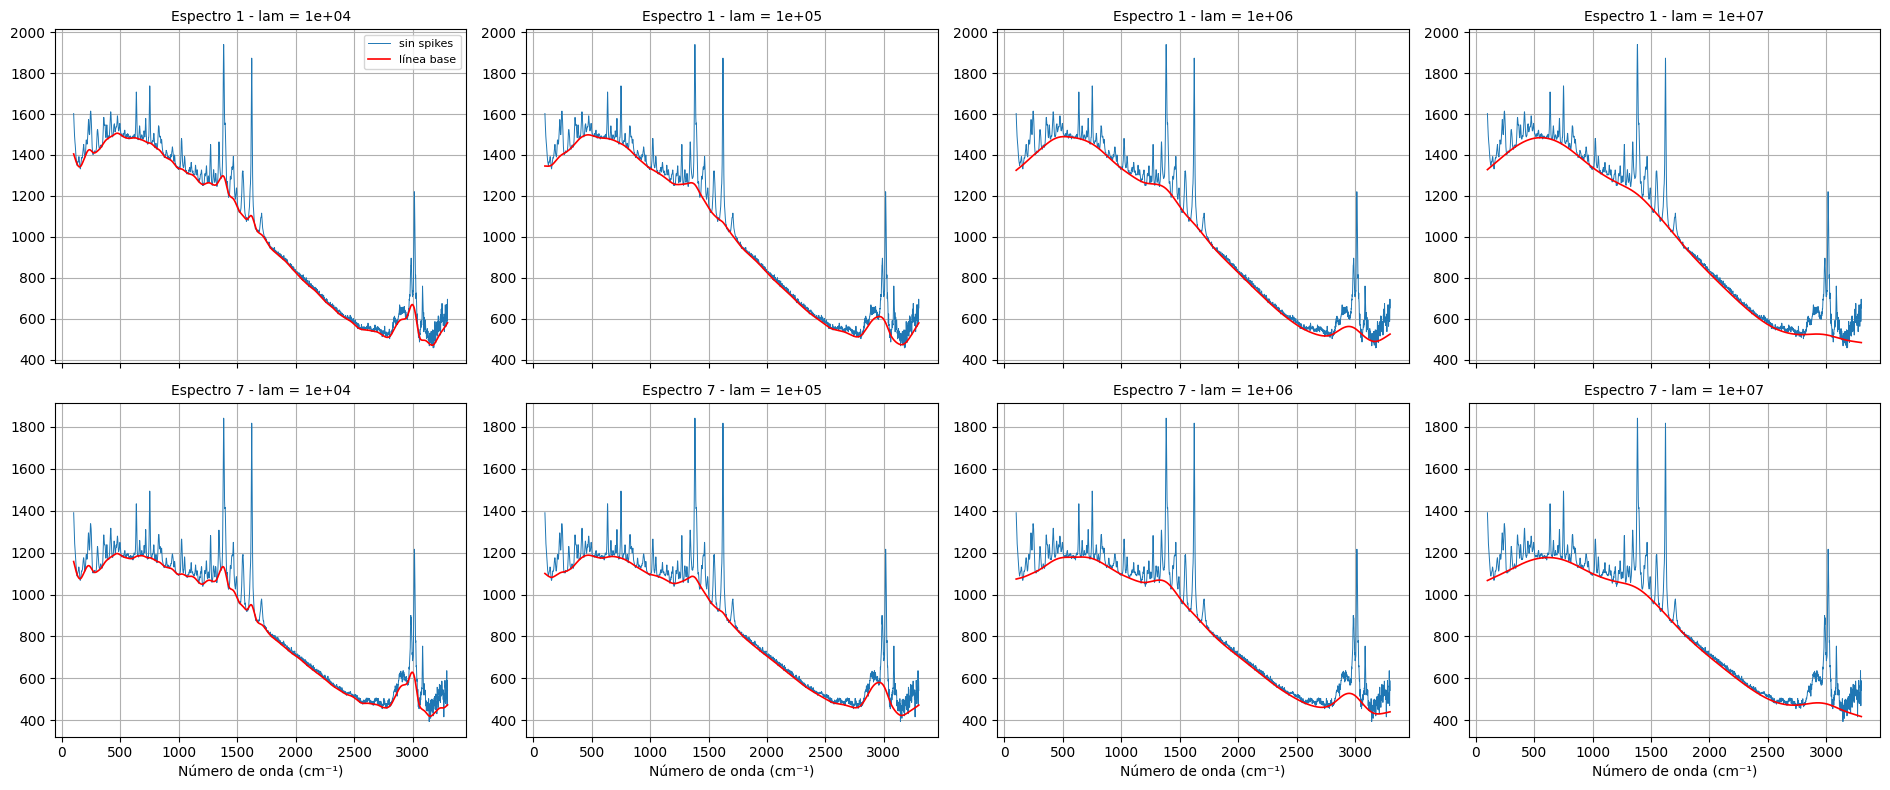

In [ ]:
# ==================================================
# 8. CORRECCIÓN DE LÍNEA BASE ALS - PRUEBA DE PARÁMETROS
# Requiere: X_sin_spikes, WD (si hubo reinicio, ejecuta antes la celda de reconstrucción)
# ==================================================
from scipy import sparse
from scipy.sparse.linalg import spsolve

def als_baseline(y, lam, p=0.01, n_iter=10):
    n = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(n, n - 2))
    penal = lam * D.dot(D.T)
    w = np.ones(n)
    for _ in range(n_iter):
        Z = sparse.spdiags(w, 0, n, n) + penal
        z = spsolve(Z.tocsc(), w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return z

lams = [1e4, 1e5, 1e6, 1e7]
casos = [1, 7]                      # espectros de prueba (numeración 1-600)

fig, ejes = plt.subplots(len(casos), len(lams), figsize=(19, 8), sharex=True)
for f, e in enumerate(casos):
    y = X_sin_spikes[e - 1]
    for c, lam in enumerate(lams):
        base = als_baseline(y, lam)
        ejes[f, c].plot(WD, y, lw=0.7, label="sin spikes")
        ejes[f, c].plot(WD, base, color="red", lw=1.2, label="línea base")
        ejes[f, c].set_title(f"Espectro {e} - lam = {lam:.0e}", fontsize=10)
        ejes[f, c].grid(True)
        if f == 0 and c == 0:
            ejes[f, c].legend(fontsize=8)
for ax in ejes[-1]:
    ax.set_xlabel("Número de onda (cm⁻¹)")
plt.tight_layout()
plt.show()

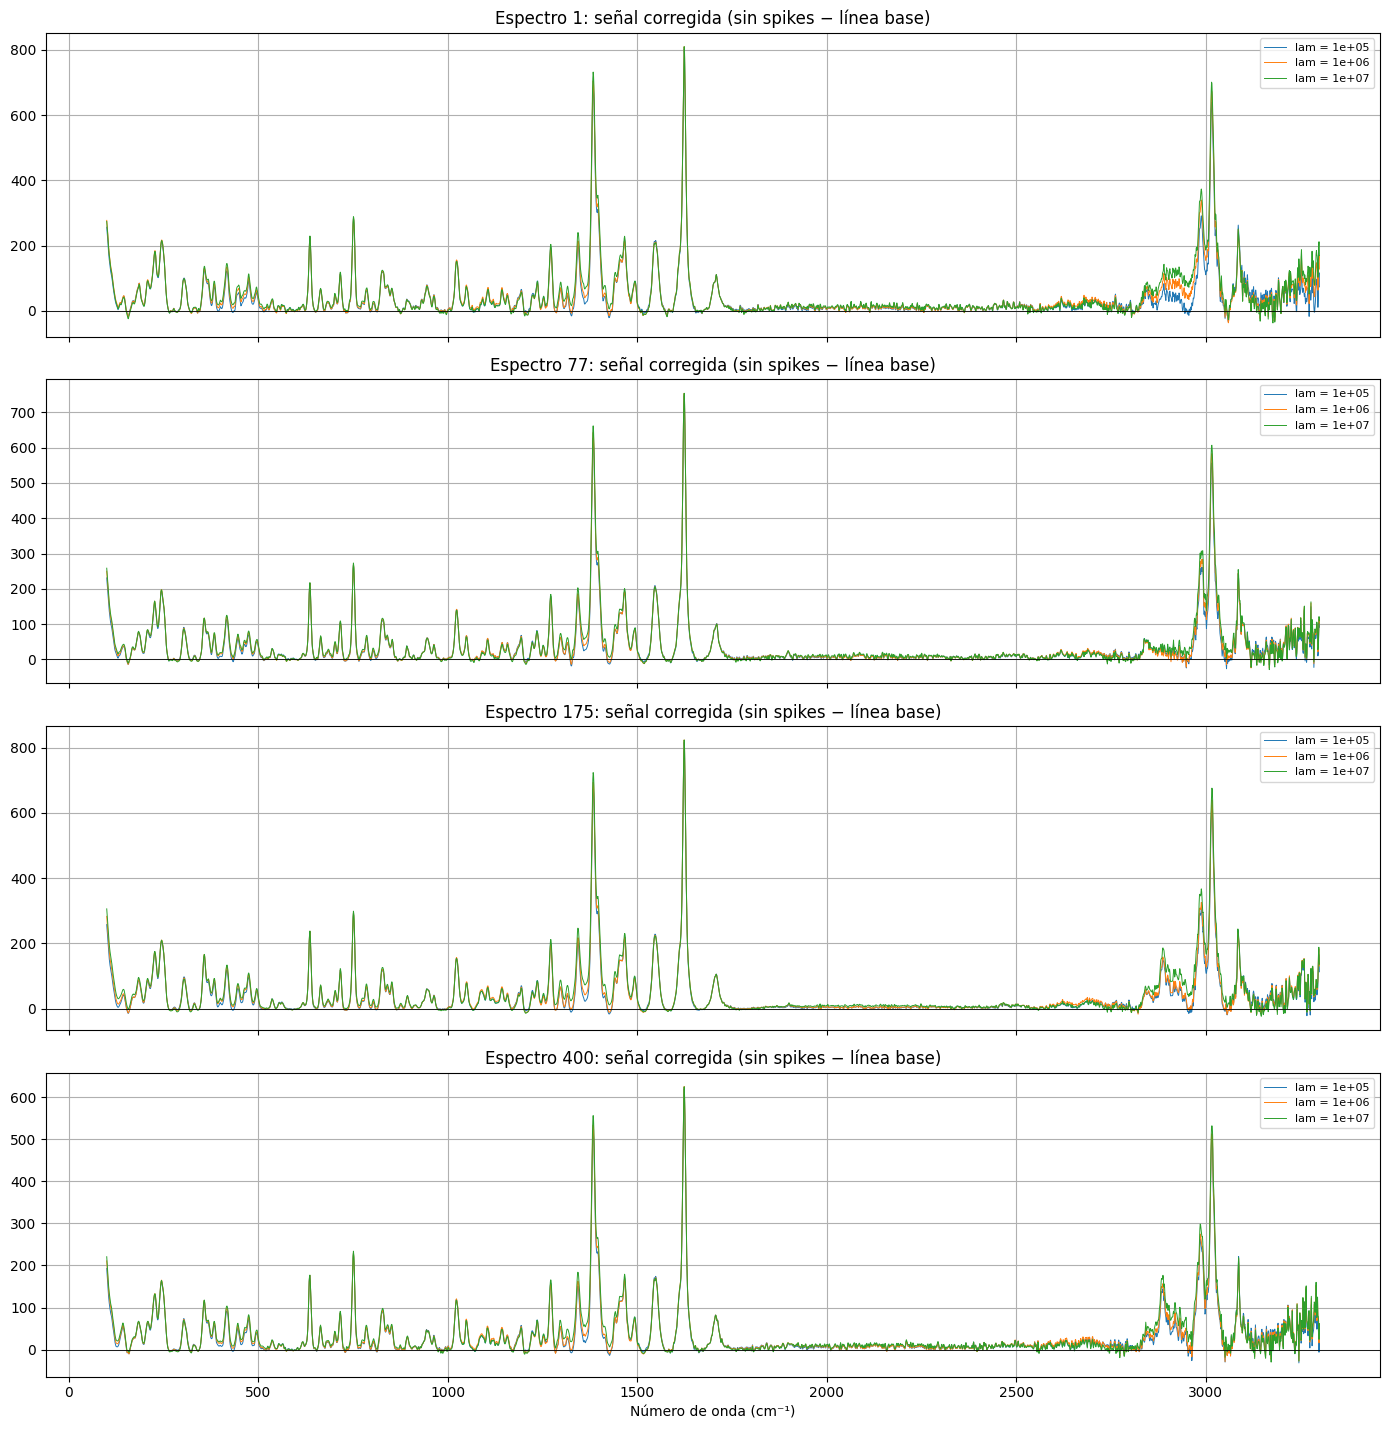

Empty DataFrame
Columns: []
Index: []


In [ ]:
#8. ALS - COMPARACIÓN DE lam SOBRE LA SEÑAL CORREGIDA (no guarda nada)
# Requiere: als_baseline, X_sin_spikes, WD
lams = [1e5, 1e6, 1e7]
casos = [1, 77, 175, 400]
zona_plana = (WD >= 2000) & (WD <= 2600)      # sin bandas: lo corregido debería quedar cerca de 0
banda = (WD >= 1610) & (WD <= 1640)           # banda de ~1623 cm-1

filas = []
fig, ejes = plt.subplots(len(casos), 1, figsize=(14, 3.6 * len(casos)), sharex=True)
for ax, e in zip(ejes, casos):
    y = X_sin_spikes[e - 1]
    for lam in lams:
        corr = y - als_baseline(y, lam)
        ax.plot(WD, corr, lw=0.7, label=f"lam = {lam:.0e}")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Espectro {e}: señal corregida (sin spikes − línea base)")
    ax.legend(fontsize=8); ax.grid(True)
ejes[-1].set_xlabel("Número de onda (cm⁻¹)")
plt.tight_layout(); plt.show()
print(pd.DataFrame(filas).to_string(index=False))